# Clase 3 — Word Embeddings

**Demostración en Python**

En las diapositivas vimos la idea: en vez de contar en qué documentos aparece una palabra (clase 2), **aprendemos** un vector corto y denso para cada palabra resolviendo una tarea de predicción sobre texto crudo.

En este notebook vamos a recorrer el mismo camino, de lo pequeño a lo grande:

1. Por qué los vectores *one-hot* no sirven para comparar palabras.
2. Cómo se fabrican los ejemplos de entrenamiento de **skip-gram** y **CBOW**.
3. Un skip-gram en miniatura, escrito a mano con `numpy`.
4. Entrenar word2vec sobre **200.000 reseñas de Amazon en español** y comparar skip-gram con CBOW.
5. Explorar el espacio: vecinos, visualización 2D, **analogías** y **sesgos**.
6. fastText y las palabras que el modelo nunca vio.
7. Usar los embeddings para **clasificar reseñas**.

Igual que en la clase pasada: antes de ejecutar un experimento, anticipen el resultado; después, veamos qué números lo explican.

In [1]:
#@title Preparación: librerías y funciones auxiliares
# En Colab solo falta gensim; en otro entorno: pip install gensim datasets scikit-learn matplotlib
try:
    import gensim
except ImportError:
    !pip install -q gensim
    import gensim

import re, time
from collections import Counter
from html import escape

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

%config InlineBackend.figure_formats = ['retina']
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

AZUL, ROJO, VERDE, NARANJO, MORADO, GRIS = "#6c8ebf", "#b85450", "#82b366", "#d79b00", "#9673a6", "#999999"

def normalizar(texto):
    """Minúsculas, solo letras (con tildes y ñ) y separación por espacios."""
    texto = texto.lower()
    texto = re.sub(r"[^a-zñáéíóúü]", " ", texto)
    return texto.split()

def coseno(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def mostrar(tabla, columnas, decimales=2):
    """Tabla legible en Jupyter y Colab, sin depender de pandas."""
    def fmt(v):
        return f"{v:.{decimales}f}" if isinstance(v, (float, np.floating)) else escape(str(v))
    encabezado = "<tr><th></th>" + "".join(f"<th>{escape(str(c))}</th>" for c in columnas) + "</tr>"
    filas = "".join(
        "<tr><th>" + escape(str(nombre)) + "</th>" + "".join(f"<td>{fmt(v)}</td>" for v in valores) + "</tr>"
        for nombre, valores in tabla.items()
    )
    display(HTML('<div style="overflow-x:auto"><table style="font-size:15px;border-spacing:12px 6px;text-align:left">'
                 + encabezado + filas + "</table></div>"))

def vecinos(kv, palabra, n=6):
    """Lista compacta de vecinos: 'palabra (0.81) · ...'."""
    if palabra not in kv:
        return "— fuera del vocabulario —"
    return " · ".join(f"{p} ({s:.2f})" for p, s in kv.most_similar(palabra, topn=n))

# 1. Las palabras como vectores: la matriz término-término

En la clase 2 representamos una palabra por los **documentos** donde aparece (matriz término-documento). Una alternativa es la matriz **término-término**: las columnas también son palabras. Cada celda cuenta cuántas veces la palabra de la fila (objetivo) aparece cerca de la palabra de la columna (contexto), dentro de una **ventana** de 4 palabras a cada lado.

Usaremos estas frases. Igual que en la clase 2, quitamos las palabras funcionales (`el`, `en`, `y`…): aparecen en todas partes y harían parecer similares a palabras que no lo son.

| | frase |
|---|---|
| 1 | el gato come pescado |
| 2 | el perro duerme en el sofá |
| 3 | el perro juega con la pelota |
| 4 | el gato juega con el ovillo |
| 5 | el auto usa gasolina y anda por la carretera |
| 6 | el camión usa gasolina y anda por la autopista |

In [2]:
frases = ["el gato come pescado",
          "el perro duerme en el sofá",
          "el perro juega con la pelota",
          "el gato juega con el ovillo",
          "el auto usa gasolina y anda por la carretera",
          "el camión usa gasolina y anda por la autopista"]
FUNCIONALES = {"a", "al", "con", "de", "del", "el", "en", "la", "las", "los", "por", "su", "un", "una", "y"}
oraciones_ej = [[p for p in f.split() if p not in FUNCIONALES] for f in frases]
for tokens in oraciones_ej:
    print(tokens)

vocabulario = []                       # en orden de aparición
for tokens in oraciones_ej:
    for palabra in tokens:
        if palabra not in vocabulario:
            vocabulario.append(palabra)
pos_vocab = {p: i for i, p in enumerate(vocabulario)}

['gato', 'come', 'pescado']
['perro', 'duerme', 'sofá']
['perro', 'juega', 'pelota']
['gato', 'juega', 'ovillo']
['auto', 'usa', 'gasolina', 'anda', 'carretera']
['camión', 'usa', 'gasolina', 'anda', 'autopista']


In [3]:
def matriz_termino_termino(oraciones, ventana=4):
    """M[i, j] = veces que la palabra j aparece a distancia <= ventana de la palabra i."""
    M = np.zeros((len(vocabulario), len(vocabulario)), dtype=int)
    for tokens in oraciones:
        for i, w in enumerate(tokens):
            for j in range(max(0, i - ventana), min(len(tokens), i + ventana + 1)):
                if j != i:
                    M[pos_vocab[w], pos_vocab[tokens[j]]] += 1
    return M

M = matriz_termino_termino(oraciones_ej)
# Mostramos los ceros como "·" para que se lean mejor los conteos.
mostrar({p: [v if v else "·" for v in M[pos_vocab[p]]] for p in vocabulario}, vocabulario)

,gato,come,pescado,perro,duerme,sofá,juega,pelota,ovillo,auto,usa,gasolina,anda,carretera,camión,autopista
gato,·,1,1,·,·,·,1,·,1,·,·,·,·,·,·,·
come,1,·,1,·,·,·,·,·,·,·,·,·,·,·,·,·
pescado,1,1,·,·,·,·,·,·,·,·,·,·,·,·,·,·
perro,·,·,·,·,1,1,1,1,·,·,·,·,·,·,·,·
duerme,·,·,·,1,·,1,·,·,·,·,·,·,·,·,·,·
sofá,·,·,·,1,1,·,·,·,·,·,·,·,·,·,·,·
juega,1,·,·,1,·,·,·,1,1,·,·,·,·,·,·,·
pelota,·,·,·,1,·,·,1,·,·,·,·,·,·,·,·,·
ovillo,1,·,·,·,·,·,1,·,·,·,·,·,·,·,·,·
auto,·,·,·,·,·,·,·,·,·,·,1,1,1,1,·,·


Lean las filas de `gato` y `perro`: ¿qué columnas comparten? Hagan lo mismo con `auto` y `camión`.

Cada fila es ahora el **vector de una palabra**, con una coordenada por palabra del vocabulario.

**Antes de ejecutar:** sabemos que un gato se parece a un perro tanto como un auto a un camión. ¿Dará la matriz cosenos parecidos para los dos pares?

In [4]:
vector = lambda p: M[pos_vocab[p]]
for a, b in [("gato", "perro"), ("auto", "camión"), ("gato", "auto")]:
    compartidas = [vocabulario[j] for j in np.nonzero(vector(a) * vector(b))[0]]
    print(f"{a:>5} – {b:<7} cos = {coseno(vector(a), vector(b)):.2f}   contextos compartidos: {compartidas}")

 gato – perro   cos = 0.25   contextos compartidos: ['juega']
 auto – camión  cos = 0.75   contextos compartidos: ['usa', 'gasolina', 'anda']
 gato – auto    cos = 0.00   contextos compartidos: []


- `auto` y `camión` aparecen en frases casi idénticas: comparten `usa`, `gasolina` y `anda`, y su coseno es alto (0,75).
- `gato` y `perro` solo comparten `juega`: coseno 0,25. Para la matriz, un gato se parece **mucho menos** a un perro que un auto a un camión.
- `gato` y `auto` no comparten nada: coseno 0.

¿Significa que los gatos no se parecen a los perros? No: el gato también podría dormir en el sofá y el perro comer pescado, pero **esas frases no están en el corpus**. La matriz término-término solo sabe lo que vio, palabra por palabra: `come` y `duerme` son columnas distintas aunque describan cosas parecidas, y un contexto que no apareció cuenta como 0.

Comparen con la representación más simple posible, el vector **one-hot**: un 1 en la coordenada de la propia palabra y 0 en las demás. Ahí todas las palabras son ortogonales, incluso `auto` y `camión`. La matriz término-término al menos captura los parecidos que el corpus muestra.

### ¿Cuál es el problema entonces?

In [5]:
print(f"Dimensión de cada vector: {M.shape[1]} (= tamaño del vocabulario)")
print(f"Celdas en cero: {np.mean(M == 0):.0%}")

Dimensión de cada vector: 16 (= tamaño del vocabulario)
Celdas en cero: 77%


Con 6 frases ya hay muchos ceros, y cada cero es un contexto que no observamos (como `gato`–`sofá`). Con el vocabulario de las 200.000 reseñas que usaremos después, cada vector tendría más de **57.000 coordenadas**, casi todas cero: vectores **largos y dispersos**, como los de la clase 2.

Un **embedding** resume esa información en pocas dimensiones con valores reales. Ninguna dimensión tiene nombre, pero palabras que aparecen en contextos parecidos terminan apuntando en direcciones parecidas. Y como los propios contextos también tienen vectores densos (`come`, `duerme` y `juega` quedan cerca entre sí), `gato` y `perro` pueden acercarse aunque no compartan exactamente las mismas palabras vecinas:

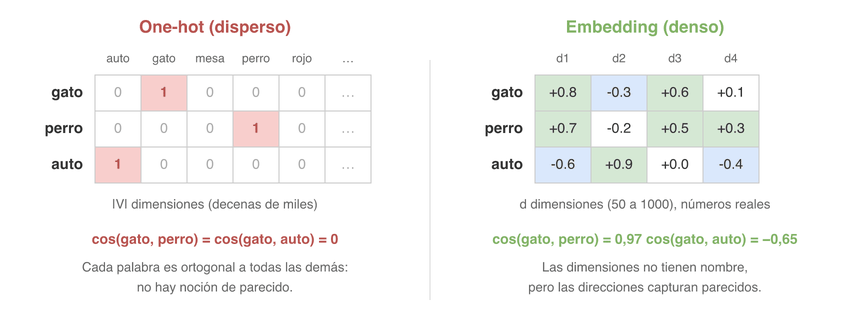

Los números de la derecha son inventados. La pregunta del resto de la clase es: **¿cómo se aprenden esos números directamente a partir de texto, sin construir la matriz completa?**

# 2. Fabricar ejemplos de entrenamiento a partir de texto crudo

word2vec es **autosupervisado**: no necesita etiquetas humanas. El propio texto genera las preguntas y las respuestas. Deslizamos una ventana sobre cada oración:

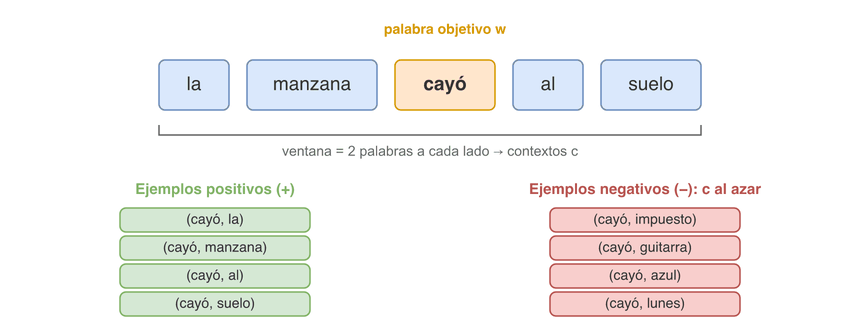

Escribamos esa ventana en código.

In [6]:
def pares_skipgram(tokens, ventana=2):
    """Skip-gram: un ejemplo (palabra objetivo, palabra de contexto) por cada vecino dentro de la ventana."""
    pares = []
    for i, w in enumerate(tokens):
        for j in range(max(0, i - ventana), min(len(tokens), i + ventana + 1)):
            if j != i:
                pares.append((w, tokens[j]))
    return pares

def ejemplos_cbow(tokens, ventana=2):
    """CBOW: un ejemplo (lista de contexto → palabra central) por posición."""
    return [([tokens[j] for j in range(max(0, i - ventana), min(len(tokens), i + ventana + 1)) if j != i], w)
            for i, w in enumerate(tokens)]

oracion = "la manzana cayó al suelo".split()
print("Skip-gram:")
for par in pares_skipgram(oracion):
    print("  ", par)

Skip-gram:
   ('la', 'manzana')
   ('la', 'cayó')
   ('manzana', 'la')
   ('manzana', 'cayó')
   ('manzana', 'al')
   ('cayó', 'la')
   ('cayó', 'manzana')
   ('cayó', 'al')
   ('cayó', 'suelo')
   ('al', 'manzana')
   ('al', 'cayó')
   ('al', 'suelo')
   ('suelo', 'cayó')
   ('suelo', 'al')


**Antes de ejecutar:** con la misma oración y la misma ventana, ¿cuántos ejemplos genera CBOW? ¿Más o menos que los 14 pares de skip-gram?

In [7]:
print("CBOW:")
for contexto, centro in ejemplos_cbow(oracion):
    print(f"   {contexto} → {centro}")

CBOW:
   ['manzana', 'cayó'] → la
   ['la', 'cayó', 'al'] → manzana
   ['la', 'manzana', 'al', 'suelo'] → cayó
   ['manzana', 'cayó', 'suelo'] → al
   ['cayó', 'al'] → suelo


CBOW genera **un ejemplo por palabra** (5) y promedia su contexto; skip-gram genera **un ejemplo por par** (14). Es la diferencia de la diapositiva:

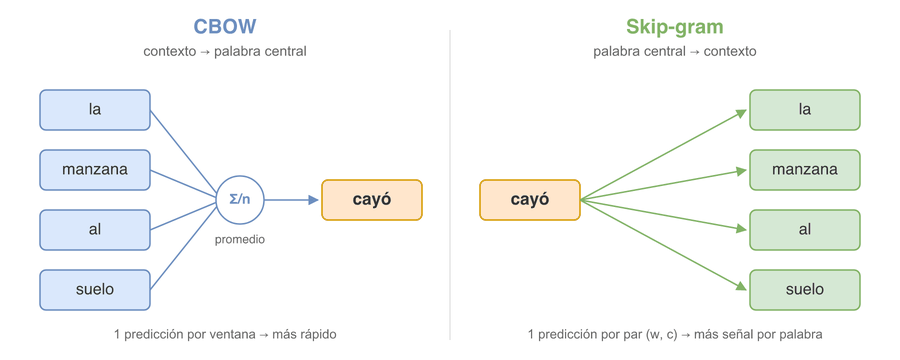

- CBOW hace menos predicciones por ventana → entrena más rápido.
- Skip-gram actualiza el vector de una palabra una vez por cada vecino → más señal para las palabras poco frecuentes.

Lo comprobaremos con datos reales en la sección 5.

# 3. Un skip-gram en miniatura

El clasificador de skip-gram responde: *¿es `c` un contexto real de `w`?* Usa el producto punto como similitud y la sigmoide para convertirlo en probabilidad:

$$
P(+\mid w, c) = \sigma(\mathbf c \cdot \mathbf w) = \frac{1}{1 + e^{-\mathbf c \cdot \mathbf w}}
$$

Por cada par positivo tomamos `k` palabras al azar como negativos (*muestreo negativo*):

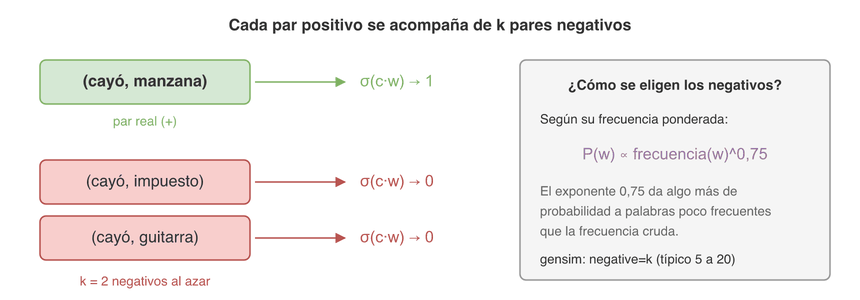

In [8]:
def sigmoide(x):
    return 1 / (1 + np.exp(-x))

for producto in [-4, -1, 0, 1, 4]:
    print(f"c·w = {producto:+d}  →  σ = {sigmoide(producto):.3f}")

c·w = -4  →  σ = 0.018
c·w = -1  →  σ = 0.269
c·w = +0  →  σ = 0.500
c·w = +1  →  σ = 0.731
c·w = +4  →  σ = 0.982


Un producto punto grande y positivo da probabilidad cercana a 1; uno negativo, cercana a 0.

Ahora entrenamos de verdad, con un corpus de juguete y **embeddings de 2 dimensiones** para poder dibujarlos. Cada palabra tiene dos vectores: uno como objetivo (`W`) y otro como contexto (`C`).

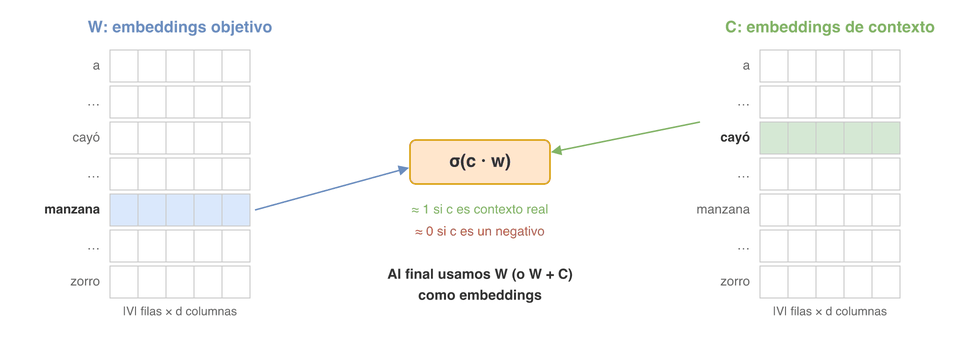

El paso de gradiente hace exactamente lo que dice la diapositiva: acerca `w` a sus contextos reales y lo aleja de los negativos.

In [9]:
corpus_juguete = [
    "el perro come carne", "el gato come pescado", "el perro duerme en casa", "el gato duerme en casa",
    "el perro corre en el parque", "el gato corre en el jardín",
    "la manzana es dulce", "la pera es dulce", "la manzana es una fruta", "la pera es una fruta",
    "la manzana cae del árbol", "la pera cae del árbol",
    "el auto anda rápido", "el camión anda lento", "el auto usa gasolina", "el camión usa gasolina",
]
oraciones = [o.split() for o in corpus_juguete]
vocab = sorted({p for o in oraciones for p in o})
idx = {p: i for i, p in enumerate(vocab)}                      # palabra → número de fila
pares = [(idx[w], idx[c]) for o in oraciones for w, c in pares_skipgram(o, ventana=2)]

# Distribución para sortear negativos: frecuencia^0,75, normalizada para que sume 1
frecuencia = Counter(p for o in oraciones for p in o)
p_neg = np.array([frecuencia[p] ** 0.75 for p in vocab]); p_neg /= p_neg.sum()
print(f"{len(vocab)} palabras, {len(pares)} pares positivos")

29 palabras, 200 pares positivos


### Un paso de aprendizaje

Para cada ejemplo (w, c) con etiqueta $y = 1$ (contexto real) o $y = 0$ (negativo), el clasificador predice $\hat y = \sigma(\mathbf c \cdot \mathbf w)$ y paga la **pérdida logística** (entropía cruzada), la misma de la regresión logística:

$$
L = -\big[\, y \log \hat y + (1 - y) \log (1 - \hat y) \,\big]
$$

Al derivar respecto de $\mathbf c \cdot \mathbf w$ queda algo muy simple: $\hat y - y$, la predicción menos la etiqueta. Lo llamamos **error**:

- par real ($y = 1$) con predicción 0,3 → error −0,7: hay que **subir** $\mathbf c \cdot \mathbf w$;
- negativo ($y = 0$) con predicción 0,8 → error +0,8: hay que **bajar** $\mathbf c \cdot \mathbf w$.

Por la regla de la cadena, los gradientes de cada vector son:

$$
\frac{\partial L}{\partial \mathbf w} = \text{error}\cdot \mathbf c \qquad\qquad \frac{\partial L}{\partial \mathbf c} = \text{error}\cdot \mathbf w
$$

y el descenso de gradiente mueve cada vector un poco (tasa de aprendizaje `lr`) en sentido contrario. Con error negativo, **w** se mueve *hacia* **c** (y **c** hacia **w**); con error positivo, se alejan.

*Ojo:* "predicción − etiqueta" se parece al error de una regresión lineal, pero aquí sale de la pérdida logística. Si usáramos error cuadrático, aparecería además un factor $\sigma'(\mathbf c \cdot \mathbf w)$ que hace el aprendizaje mucho más lento cuando el clasificador se equivoca con mucha seguridad.

In [10]:
def paso(W, C, w, ctx, etiqueta, lr):
    """Actualiza W[w] y C[ctx] con un ejemplo (w, ctx) de etiqueta 1 (real) o 0 (negativo)."""
    error = sigmoide(C[ctx] @ W[w]) - etiqueta    # predicción − etiqueta
    grad_w, grad_c = error * C[ctx], error * W[w]  # gradientes (antes de modificar nada)
    W[w] -= lr * grad_w
    C[ctx] -= lr * grad_c

Probémoslo con un solo par real, (`perro`, `come`), y un negativo, (`perro`, `gasolina`), partiendo de vectores al azar. **Antes de ejecutar:** ¿qué debería pasar con σ(**c**·**w**) en cada caso después de varios pasos?

In [11]:
rng = np.random.default_rng(1)
W_demo = rng.normal(0, 0.5, (len(vocab), 2))
C_demo = rng.normal(0, 0.5, (len(vocab), 2))
prob = lambda w, c: sigmoide(C_demo[idx[c]] @ W_demo[idx[w]])

print(f"Al inicio:          P(+|perro, come) = {prob('perro', 'come'):.2f}   P(+|perro, gasolina) = {prob('perro', 'gasolina'):.2f}")
for _ in range(20):
    paso(W_demo, C_demo, idx["perro"], idx["come"], 1, lr=0.5)       # par real → acercar
    paso(W_demo, C_demo, idx["perro"], idx["gasolina"], 0, lr=0.5)   # negativo → alejar
print(f"Después de 20 pasos: P(+|perro, come) = {prob('perro', 'come'):.2f}   P(+|perro, gasolina) = {prob('perro', 'gasolina'):.2f}")

Al inicio:          P(+|perro, come) = 0.51   P(+|perro, gasolina) = 0.49
Después de 20 pasos: P(+|perro, come) = 0.99   P(+|perro, gasolina) = 0.02


### ¿Es esto exactamente word2vec? Una simplificación

**1. El objetivo original era otro.** El skip-gram de Mikolov et al. (2013a) predice la palabra de contexto entre **todas** las del vocabulario, con un *softmax*:

$$
P(c \mid w) = \frac{e^{\mathbf c \cdot \mathbf w}}{\sum_{v \in V} e^{\mathbf v \cdot \mathbf w}}
\qquad\Rightarrow\qquad
\frac{\partial (-\log P(c\mid w))}{\partial \mathbf w} = -\mathbf c + \sum_{v \in V} P(v \mid w)\, \mathbf v
$$

El gradiente necesita recorrer las $|V|$ palabras (decenas de miles) **en cada ejemplo**: demasiado caro.

**2. El muestreo negativo lo aproxima.** Mikolov et al. (2013b) reemplazan esa pregunta de opción múltiple por varias preguntas de sí/no: ¿es `c` un contexto real? ¿y cada uno de estos `k` negativos? El objetivo para un par positivo es

$$
\log \sigma(\mathbf c \cdot \mathbf w) + \sum_{i=1}^{k} \log \sigma(-\mathbf n_i \cdot \mathbf w)
$$

que es exactamente la suma de las pérdidas logísticas que usa nuestro `paso` (etiqueta 1 para `c`, etiqueta 0 para cada `n_i`). Solo toca $k + 1$ palabras por ejemplo en vez de $|V|$. Ya no estima $P(c \mid w)$ como un softmax, pero en la práctica produce muy buenos embeddings a una fracción del costo; en el paper superó al *softmax jerárquico*, la otra aproximación que proponían.

**3. Además, nuestro código simplifica la implementación real de word2vec:**

| aquí | en word2vec |
|---|---|
| actualizamos **w** después de cada ejemplo (positivo y luego cada negativo) | acumula el gradiente del positivo y los `k` negativos y actualiza **w** una sola vez |
| tasa de aprendizaje `lr` constante | `lr` decrece linealmente durante el entrenamiento |
| todas las palabras participan igual | descarta al azar parte de las palabras muy frecuentes (*subsampling*: `el`, `de`, `que`…) |
| ventana fija | sortea el tamaño de la ventana en cada posición, dando más peso a los vecinos cercanos |
| `W` y `C` al azar | `W` con valores pequeños al azar y `C` en cero |

Ninguna de estas diferencias cambia la idea central: acercar cada palabra a sus contextos reales y alejarla de palabras al azar.

### El entrenamiento completo

`entrenar_sgns` (*skip-gram with negative sampling*) repite ese paso sobre todo el corpus:

| parámetro | significado |
|---|---|
| `pares` | lista de pares positivos (objetivo, contexto) que fabricamos con la ventana |
| `V` | tamaño del vocabulario: número de filas de `W` y `C` |
| `d=2` | dimensiones de cada embedding (2 para poder dibujarlos; en la práctica 100–300) |
| `k=3` | negativos sorteados por cada par positivo |
| `epocas=300` | cuántas veces se recorre la lista completa de pares |
| `lr=0.05` | tasa de aprendizaje: cuánto se mueve cada vector en un paso |
| `semilla=0` | fija el azar (vectores iniciales, orden y negativos) para que el resultado sea reproducible |

En cada época:

1. Se baraja el orden de los pares.
2. Para cada par positivo (w, c) se sortean `k` palabras con la distribución `p_neg`.
3. Se aplica `paso` una vez con (w, c, 1) y una vez con cada negativo (w, n, 0).

Devuelve `W` antes y después de entrenar, para comparar. `C` se descarta: como en word2vec, nos quedamos con los embeddings objetivo.

In [12]:
def entrenar_sgns(pares, V, d=2, k=3, epocas=300, lr=0.05, semilla=0):
    rng = np.random.default_rng(semilla)
    W = rng.normal(0, 0.5, (V, d))      # embeddings objetivo: una fila por palabra, al azar
    C = rng.normal(0, 0.5, (V, d))      # embeddings de contexto
    W_inicial = W.copy()
    for _ in range(epocas):
        for w, c in rng.permutation(pares):                 # 1. pares en orden aleatorio
            negativos = rng.choice(V, size=k, p=p_neg)       # 2. k negativos según frecuencia^0,75
            paso(W, C, w, c, 1, lr)                          # 3. acercar w al contexto real
            for n in negativos:
                paso(W, C, w, n, 0, lr)                      #    alejar w de cada negativo
    return W_inicial, W

W_inicial, W_final = entrenar_sgns(pares, len(vocab))

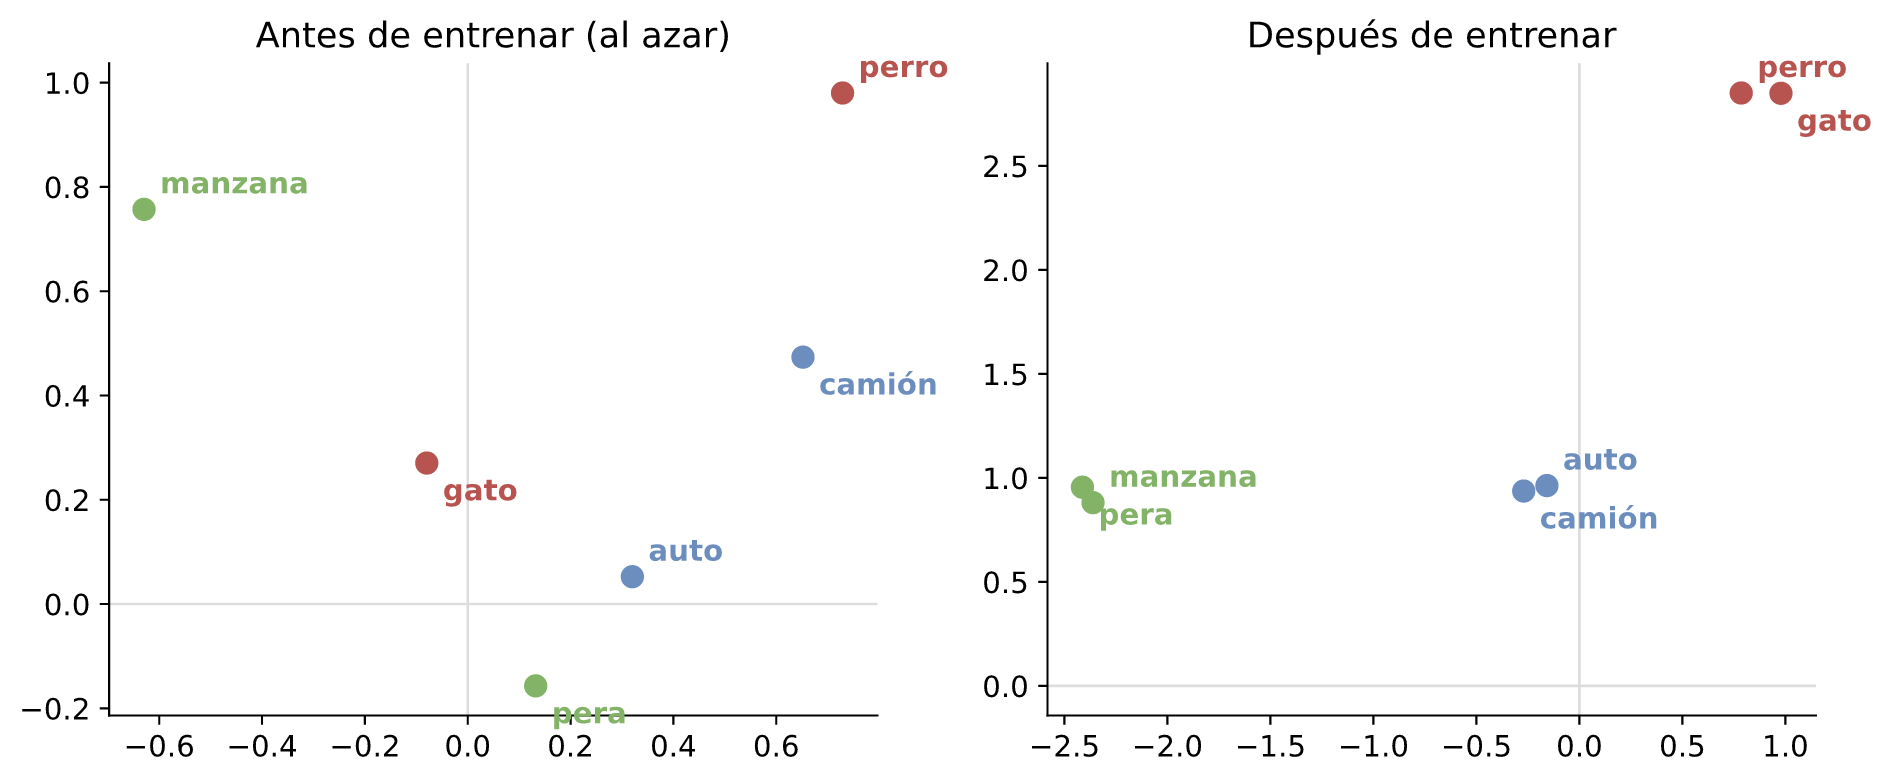

cos(perro, gato): antes +0.60  →  después +1.00
cos(manzana, pera): antes -1.00  →  después +1.00
cos(perro, manzana): antes +0.24  →  después +0.09


In [13]:
grupos = {"animales": (["perro", "gato"], ROJO), "frutas": (["manzana", "pera"], VERDE), "vehículos": (["auto", "camión"], AZUL)}

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, M, titulo in [(ejes[0], W_inicial, "Antes de entrenar (al azar)"), (ejes[1], W_final, "Después de entrenar")]:
    for nombre, (palabras, color) in grupos.items():
        for k, p in enumerate(palabras):
            x, y = M[idx[p]]
            ax.scatter(x, y, color=color, s=60, zorder=3)
            # la segunda palabra del grupo va debajo, para que no se tapen si quedan juntas
            ax.annotate(p, (x, y), xytext=(6, 6 if k == 0 else -14), textcoords="offset points", color=color, fontweight="bold")
    ax.set_title(titulo)
    ax.axhline(0, color="#ddd", lw=1); ax.axvline(0, color="#ddd", lw=1)
plt.tight_layout(); plt.show()

for a, b in [("perro", "gato"), ("manzana", "pera"), ("perro", "manzana")]:
    print(f"cos({a}, {b}): antes {coseno(W_inicial[idx[a]], W_inicial[idx[b]]):+.2f}  →  después {coseno(W_final[idx[a]], W_final[idx[b]]):+.2f}")

Nadie le dijo al modelo que `perro` y `gato` son animales. Terminan cerca porque **comparten contextos** (`come`, `duerme`, `corre`): es la hipótesis distribucional de la clase 2, ahora aprendida por descenso de gradiente.

**Para pensar:** cambien `semilla` y vuelvan a entrenar. ¿Cambian las coordenadas? ¿Cambian los grupos? (Las dimensiones no tienen significado propio; las *relaciones* sí.)

`gensim` hace exactamente esto, pero optimizado en C, con millones de pares y 100 o 300 dimensiones.

# 4. Un corpus real: reseñas de Amazon en español

## La librería `gensim`

Nuestro skip-gram de juguete recorre los pares con bucles de Python: con millones de pares sería lentísimo. Para corpus reales usaremos [**gensim**](https://radimrehurek.com/gensim/), una librería de Python para modelos de texto no supervisados (word2vec, fastText, doc2vec, LDA…). Implementa el mismo algoritmo en C optimizado, entrena en paralelo con varios núcleos y procesa el corpus sin cargarlo entero en memoria.

Las piezas que usaremos hoy:

| pieza | para qué sirve |
|---|---|
| `gensim.models.Word2Vec(oraciones, sg=1, ...)` | entrena word2vec (`sg=1` skip-gram, `sg=0` CBOW) |
| `gensim.models.FastText(oraciones, ...)` | entrena fastText (sección 10) |
| `modelo.wv` | los vectores aprendidos, un objeto `KeyedVectors` (la matriz `W`) |
| `wv["palabra"]` | el vector de una palabra |
| `wv.most_similar("palabra")` | vecinos más cercanos por coseno |
| `wv.similarity(a, b)` | coseno entre dos palabras |
| `KeyedVectors.load_word2vec_format(archivo)` | carga vectores preentrenados (sección 7) |

La entrada es simplemente **una lista de oraciones, cada una una lista de tokens**: lo mismo que `oraciones` en el ejemplo de juguete. Probémoslo con ese corpus:

In [14]:
juguete = gensim.models.Word2Vec(
    oraciones,          # lista de listas de tokens
    sg=1,               # 1 = skip-gram, 0 = CBOW
    vector_size=10,     # d: dimensiones del embedding
    window=2,           # palabras de contexto a cada lado
    negative=3,         # k: negativos por par positivo
    min_count=1,        # frecuencia mínima para entrar al vocabulario
    sample=0,           # sin subsampling de palabras frecuentes (ver nota abajo)
    epochs=300,         # pasadas por el corpus
    seed=0, workers=1,  # reproducible (un solo hilo)
)

print("Vocabulario:", len(juguete.wv), "palabras ×", juguete.wv.vector_size, "dimensiones")
print("Vector de 'perro':", np.round(juguete.wv["perro"], 2))
print("Vecinos de 'perro':", [p for p, _ in juguete.wv.most_similar("perro", topn=3)])
for a, b in [("perro", "gato"), ("manzana", "pera"), ("auto", "camión"), ("perro", "manzana")]:
    print(f"similarity({a}, {b}) = {juguete.wv.similarity(a, b):.2f}")

Vocabulario: 29 palabras × 10 dimensiones
Vector de 'perro': [ 1.03  0.05 -0.51 -0.17  0.75  0.29 -2.48  0.48  0.59  0.17]
Vecinos de 'perro': ['gato', 'parque', 'jardín']
similarity(perro, gato) = 1.00
similarity(manzana, pera) = 1.00
similarity(auto, camión) = 0.99
similarity(perro, manzana) = 0.29


Los conceptos de la sección anterior tienen nombre propio en gensim: `vector_size` es `d`, `negative` es `k`, `epochs` son las épocas, y `wv` guarda la matriz `W` (gensim también aprende los vectores de contexto `C`, pero no los usamos).

**Sobre `sample`:** por defecto (`sample=0.001`) gensim descarta al azar parte de las apariciones de las palabras más frecuentes (el *subsampling* de la tabla de la sección 3). En un corpus real eso ahorra tiempo y mejora los vectores; en 16 frases, donde casi todas las palabras son "frecuentes", eliminaría la mayoría de los ejemplos. Prueben quitar `sample=0` y vuelvan a ejecutar.

## Las reseñas

Usaremos el conjunto `amazon_reviews_multi` (partición en español): 200.000 reseñas de entrenamiento y 5.000 de prueba, cada una con su número de estrellas (0 = ★, 4 = ★★★★★). Para word2vec las estrellas no importan: solo necesita el texto. Las usaremos al final para clasificar.

In [15]:
import datasets

URL = "https://huggingface.co/datasets/mteb/amazon_reviews_multi/resolve/main/es/"
resenas = datasets.load_dataset("json", data_files={s: URL + s + ".jsonl" for s in ["train", "test"]})
resenas

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})

In [16]:
for ejemplo in resenas["train"].shuffle(seed=1).select(range(4)):
    print("★" * (ejemplo["label"] + 1), "|", ejemplo["text"][:150].replace("\n", " "))

★★ | Deja marca en la pizarra  Hace su función pero al dejarlo pegado en la pizarra, deja las marcas de los imanes. He intentado borrarlas y es imposible.
★★★★★ | Solar para la cara fluido y con zinc!  Es lo que buscaba en términos de ingredientes para un solar y de momento estoy contenta! Había visto reviews mu
★★ | Producto usado  Me parece lamentable que te den un producto como nuevo cuando se ve claramente que está usado. Si se compra como nuevo que sea nuevo y
★★★★★ | Me gusta  Me gusta mucho este producto porque no te deja la cara pringosa ni blanca. Todo un descubrimiento


In [17]:
tokens_train = [normalizar(t) for t in resenas["train"]["text"]]
tokens_test = [normalizar(t) for t in resenas["test"]["text"]]

frecuencias = Counter(p for t in tokens_train for p in t)
print(f"{len(tokens_train):,} reseñas · {sum(frecuencias.values()):,} tokens · {len(frecuencias):,} palabras distintas")
print(f"Largo promedio: {np.mean([len(t) for t in tokens_train]):.1f} palabras")
print("Más frecuentes:", [p for p, _ in frecuencias.most_common(15)])

200,000 reseñas · 6,184,584 tokens · 57,241 palabras distintas
Largo promedio: 30.9 palabras
Más frecuentes: ['de', 'que', 'y', 'la', 'no', 'el', 'es', 'en', 'lo', 'muy', 'se', 'para', 'a', 'un', 'me']


Muchas palabras aparecen pocas veces (errores de tipeo, nombres de productos…). `min_count=5` las descarta: no hay suficiente contexto para aprender un buen vector.

# 5. Skip-gram vs. CBOW, con los mismos datos

En `gensim` cambiar de método es un solo parámetro: `sg=1` (skip-gram) o `sg=0` (CBOW). Dejamos todo lo demás igual:

| parámetro | valor | significado |
|---|---|---|
| `vector_size` | 100 | dimensiones del embedding |
| `window` | 5 | palabras de contexto a cada lado |
| `min_count` | 5 | frecuencia mínima para entrar al vocabulario |
| `negative` | 10 | negativos por cada par positivo (k) |
| `epochs` | 5 | pasadas por el corpus |

**Antes de ejecutar:** ¿cuál de los dos tardará más? ¿Cuántas veces más?

In [18]:
parametros = dict(vector_size=100, window=5, min_count=5, negative=10, epochs=5, workers=4, seed=0)

t0 = time.time()
skipgram = gensim.models.Word2Vec(tokens_train, sg=1, **parametros).wv
t_sg = time.time() - t0

t0 = time.time()
cbow = gensim.models.Word2Vec(tokens_train, sg=0, **parametros).wv
t_cbow = time.time() - t0

print(f"Skip-gram: {t_sg:5.1f} s")
print(f"CBOW:      {t_cbow:5.1f} s   ({t_sg / t_cbow:.1f} veces más rápido)")
print(f"Vocabulario: {len(skipgram):,} palabras × {skipgram.vector_size} dimensiones")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Skip-gram:  29.2 s
CBOW:       13.0 s   (2.2 veces más rápido)
Vocabulario: 22,575 palabras × 100 dimensiones


In [19]:
print("Vector de 'calidad' (primeras 10 de 100 dimensiones):")
print(np.round(skipgram["calidad"][:10], 2))

Vector de 'calidad' (primeras 10 de 100 dimensiones):
[ 0.23 -0.53  0.01  0.46 -0.01 -0.45  0.23 -0.27  0.19 -0.12]


Un vector denso de números reales: ninguna coordenada se puede leer por sí sola. Para entenderlo, miremos a sus **vecinos más cercanos** (coseno).

### Palabras frecuentes vs. poco frecuentes

La diapositiva decía: CBOW representa mejor las palabras frecuentes; skip-gram, las poco frecuentes. Pongámoslo a prueba. La columna `n` es la frecuencia en el corpus.

In [20]:
def comparar(palabras, modelos, n=5):
    tabla = {p: [frecuencias[p]] + [vecinos(m, p, n) for m in modelos.values()] for p in palabras}
    mostrar(tabla, ["n"] + list(modelos))

comparar(["calidad", "bueno", "envío", "zapatillas", "rojo"], {"skip-gram": skipgram, "CBOW": cbow})

,n,skip-gram,CBOW
calidad,47541,caludad (0.87) · cálidad (0.85) · validad (0.81) · qualidad (0.81) · buna (0.80),terminación (0.72) · apariencia (0.67) · cálidad (0.66) · presentacion (0.65) · elección (0.61)
bueno,9954,formidable (0.78) · flojillo (0.78) · buna (0.77) · bie (0.77) · moderadamente (0.77),mejorable (0.67) · malo (0.67) · buen (0.63) · normalito (0.63) · estupendo (0.62)
envío,4228,envio (0.84) · envió (0.83) · entrega (0.80) · pactado (0.75) · trámite (0.73),envio (0.84) · envió (0.79) · entrega (0.70) · embalaje (0.65) · reparto (0.64)
zapatillas,409,botas (0.83) · chanclas (0.81) · comodísimas (0.74) · cómodas (0.74) · deportivas (0.72),botas (0.90) · chanclas (0.86) · almohadas (0.84) · mallas (0.82) · plantillas (0.82)
rojo,496,azul (0.90) · verde (0.90) · amarillo (0.86) · gris (0.84) · turquesa (0.84),verde (0.92) · amarillo (0.91) · azul (0.91) · rosa (0.86) · gris (0.85)


Con palabras frecuentes, **CBOW** da listas más "limpias" (`calidad → terminación, apariencia, presentación`), mientras skip-gram llena la lista de `calidad` con variantes mal escritas (`cálidad`, `caludad`, `qualidad`): comparten exactamente los mismos contextos que la palabra bien escrita, y skip-gram las aprende bien aunque sean raras.

Fíjense también en `bueno`: en CBOW su vecino más cercano es **`malo`**. Antónimos como `bueno`/`malo` aparecen en contextos casi idénticos (*"la calidad es muy ___"*), y el modelo distribucional los acerca. Parecido distribucional no es sinonimia (lo mismo vimos en la clase 2 con `caliente`/`frío`).

Ahora, palabras con pocas apariciones:

In [21]:
comparar(["descosido", "pelusa", "amarillento", "holgado"], {"skip-gram": skipgram, "CBOW": cbow})

,n,skip-gram,CBOW
descosido,222,descosió (0.80) · descosida (0.79) · deshilachado (0.78) · agrietado (0.78) · rajado (0.78),rajado (0.90) · oxidado (0.87) · agrietado (0.87) · despegado (0.85) · partido (0.84)
pelusa,93,pelusilla (0.81) · pelusas (0.76) · pelusillas (0.75) · trapo (0.72) · esmaltado (0.72),pelusilla (0.75) · suciedad (0.75) · grasa (0.72) · pelusas (0.71) · masa (0.70)
amarillento,45,anaranjado (0.84) · rosado (0.83) · clarito (0.82) · rojizo (0.82) · azulado (0.82),clarito (0.83) · amarillo (0.81) · marrón (0.81) · marron (0.80) · beige (0.80)
holgado,36,holgada (0.84) · olgada (0.83) · alargado (0.82) · pequeñísimo (0.79) · ceñido (0.79),holgada (0.86) · tirante (0.75) · ajustada (0.75) · inclinado (0.72) · sujeto (0.71)


Con pocas apariciones, skip-gram suele mantener vecinos del mismo tipo (`pelusa → pelusilla, polvillo`; `descosido → descosió, deshilachado`; `amarillento → rojizo, anaranjado`), mientras CBOW mezcla más (`pelusa → masa, pulpa`). No es una regla absoluta: en `holgado` ambos funcionan bien.

**Para discutir:** ¿por qué entrenar con un ejemplo por cada vecino ayuda justo a las palabras raras? ¿Y por qué promediar el contexto (CBOW) favorece a las frecuentes?

# 6. Similitud entre palabras

`similarity` calcula el coseno entre dos vectores. Ordenen estos pares de más a menos parecidos **antes de ejecutar**:

In [22]:
pares_prueba = [("pantalla", "cristal"), ("pantalla", "batería"), ("pantalla", "cable"),
                ("pantalla", "zapatillas")]
for a, b in pares_prueba:
    print(f"{a:>9} – {b:<11} skip-gram {skipgram.similarity(a, b):.2f}   CBOW {cbow.similarity(a, b):.2f}")

 pantalla – cristal     skip-gram 0.74   CBOW 0.57
 pantalla – batería     skip-gram 0.47   CBOW 0.34
 pantalla – cable       skip-gram 0.36   CBOW 0.10
 pantalla – zapatillas  skip-gram 0.10   CBOW -0.28


Y la palabra que no encaja (`doesnt_match` busca la más alejada del promedio del grupo):

In [23]:
for grupo in [["rojo", "azul", "verde", "batería"],
              ["camiseta", "pantalón", "vestido", "auriculares"],
              ["rápido", "puntual", "pronto", "roto"]]:
    print(grupo, "→", skipgram.doesnt_match(grupo))

['rojo', 'azul', 'verde', 'batería'] → batería
['camiseta', 'pantalón', 'vestido', 'auriculares'] → auriculares
['rápido', 'puntual', 'pronto', 'roto'] → roto


# 7. Visualizar embeddings

Un vector de 100 dimensiones no se puede dibujar. Dos soluciones:

1. **Listar vecinos** — lo que hicimos arriba.
2. **Proyectar a 2D** — con PCA (lineal, conserva las direcciones de mayor varianza) o t-SNE (no lineal, conserva vecindarios locales).

Tomamos cinco grupos de palabras y vemos si se agrupan.

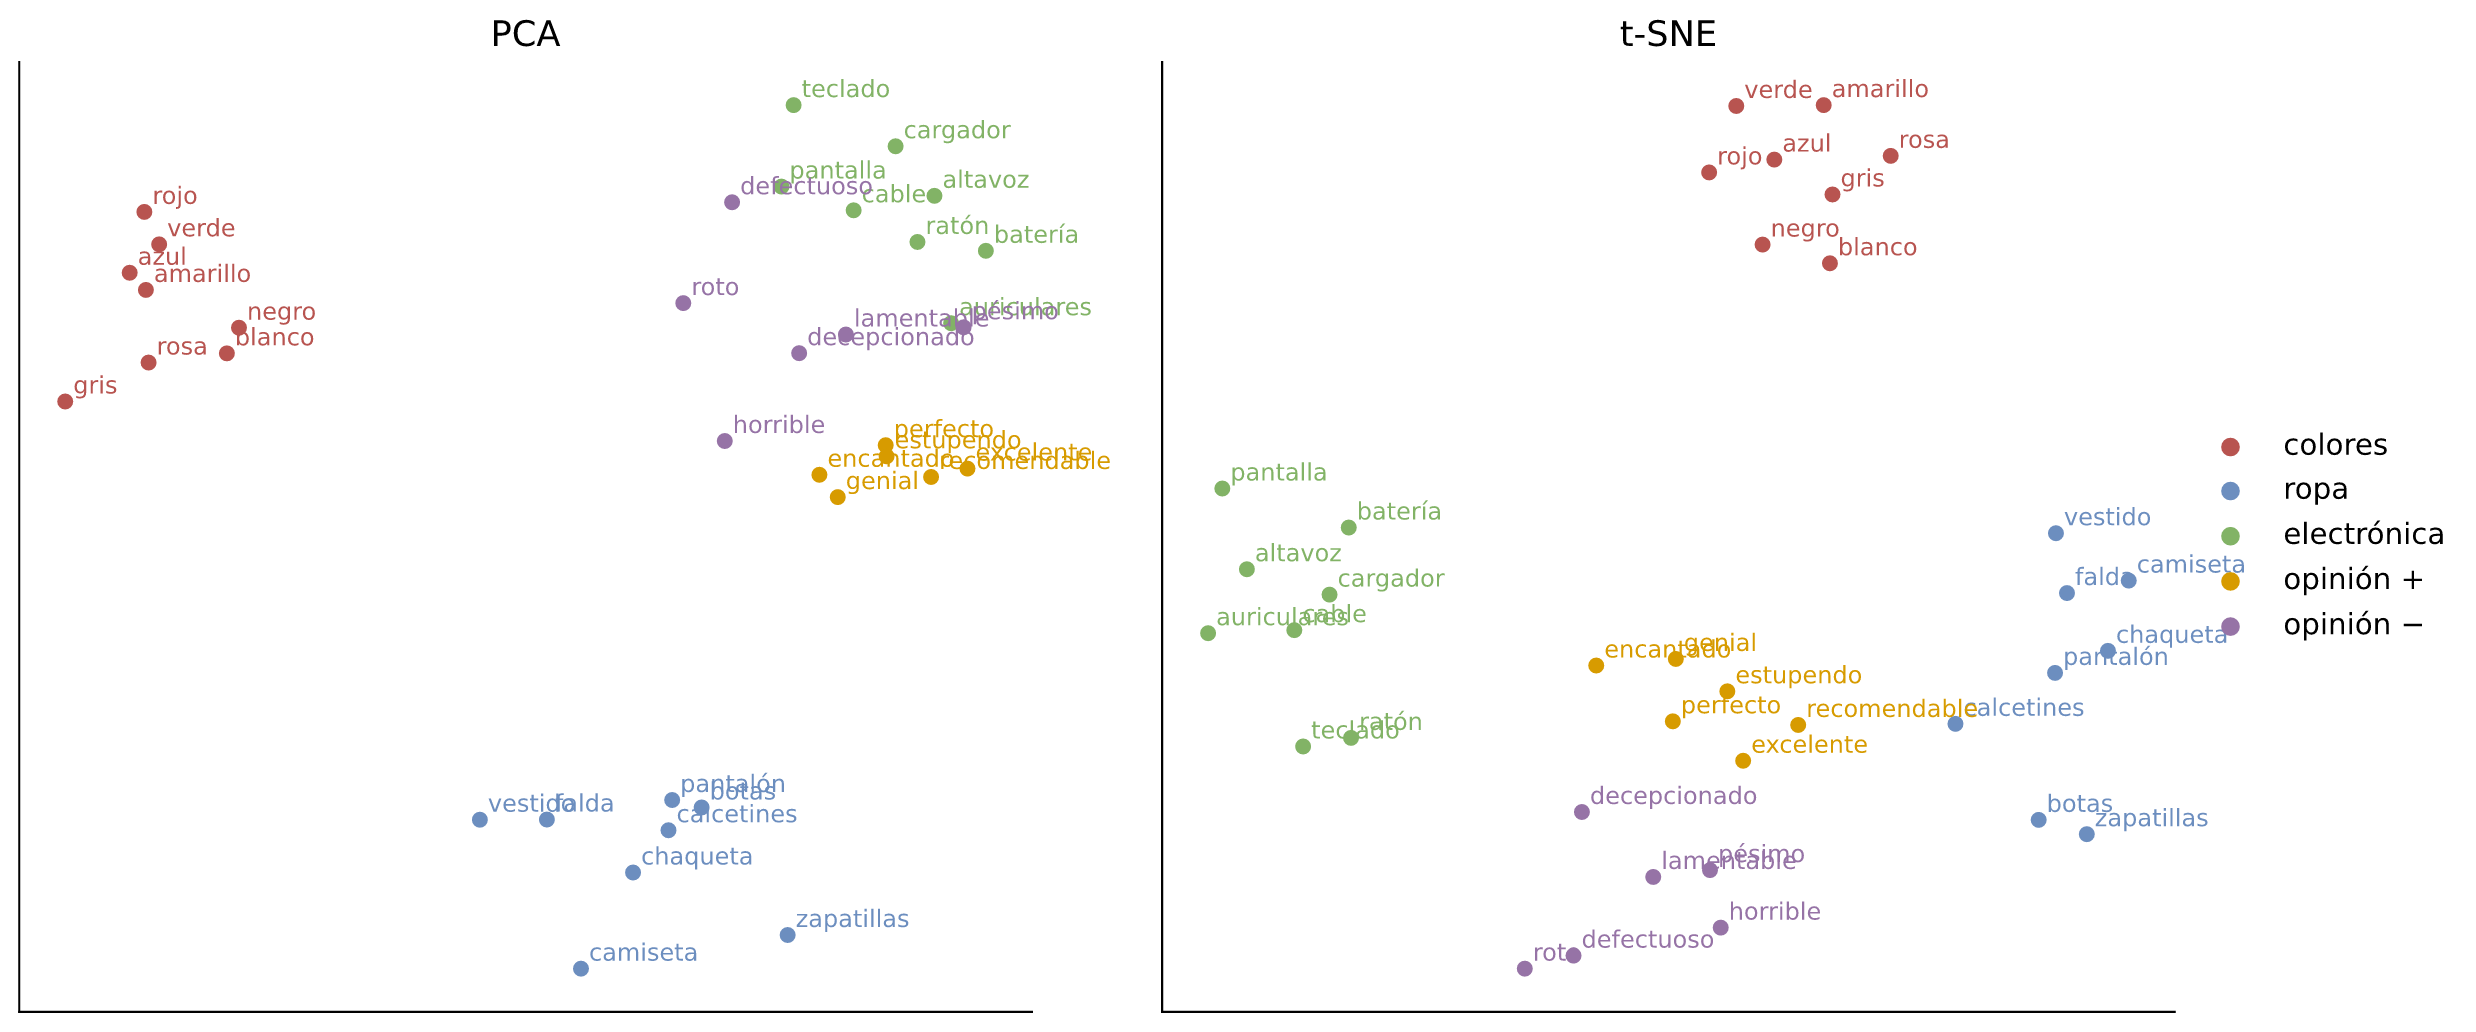

In [24]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

categorias = {
    "colores":     (["rojo", "azul", "verde", "negro", "blanco", "amarillo", "rosa", "gris"], ROJO),
    "ropa":        (["camiseta", "pantalón", "vestido", "zapatillas", "chaqueta", "calcetines", "botas", "falda"], AZUL),
    "electrónica": (["pantalla", "batería", "cable", "cargador", "auriculares", "teclado", "ratón", "altavoz"], VERDE),
    "opinión +":   (["perfecto", "genial", "excelente", "estupendo", "encantado", "recomendable"], NARANJO),
    "opinión −":   (["horrible", "pésimo", "decepcionado", "defectuoso", "roto", "lamentable"], MORADO),
}

def proyectar(kv, categorias, metodo="pca"):
    palabras = [p for ps, _ in categorias.values() for p in ps if p in kv]
    X = np.array([kv[p] for p in palabras])
    if metodo == "pca":
        Y = PCA(n_components=2).fit_transform(X)
    else:
        Y = TSNE(n_components=2, perplexity=8, init="pca", random_state=0).fit_transform(X)
    return dict(zip(palabras, Y))

def dibujar(puntos, categorias, ax, titulo):
    for nombre, (palabras, color) in categorias.items():
        for p in palabras:
            if p in puntos:
                x, y = puntos[p]
                ax.scatter(x, y, color=color, s=25)
                ax.annotate(p, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=9, color=color)
        ax.scatter([], [], color=color, label=nombre)
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5))
dibujar(proyectar(skipgram, categorias, "pca"), categorias, ejes[0], "PCA")
dibujar(proyectar(skipgram, categorias, "tsne"), categorias, ejes[1], "t-SNE")
ejes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout(); plt.show()

Ambas proyecciones separan los grupos, pero **cuidado al interpretarlas**:

- En PCA las distancias globales son más fieles, pero dos dimensiones conservan solo una parte de la varianza.
- En t-SNE los grupos se ven más nítidos, pero las distancias *entre* grupos y el tamaño de los grupos no significan mucho.
- Una proyección es una sombra del espacio original: confirmen cualquier conclusión con el coseno en 100 dimensiones.

### Proyectar sobre una dirección con significado

PCA y t-SNE eligen los ejes por nosotros, y esos ejes no tienen nombre. Otra opción es **elegir un eje con significado** y medir cuánto se inclina cada palabra hacia un lado u otro. Bolukbasi et al. (2016) lo hicieron con la dirección **he − she** en embeddings de noticias en inglés.

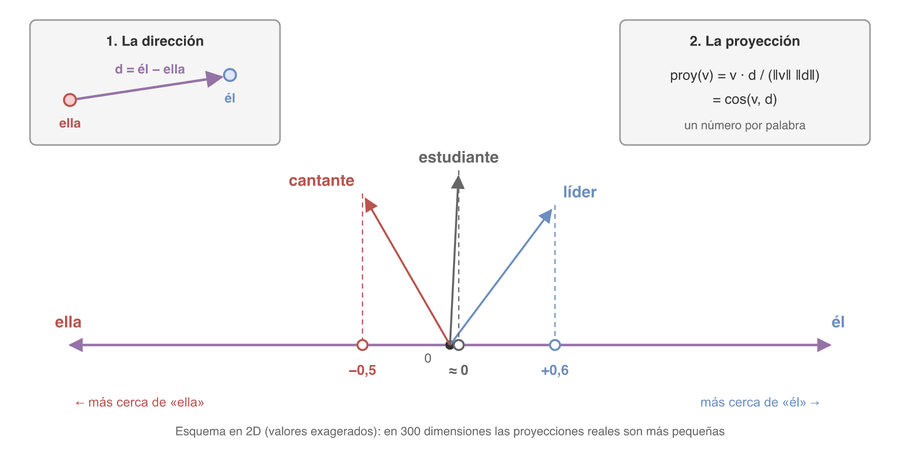

1. Restamos dos vectores que difieren solo en la propiedad que nos interesa: `d = él − ella` apunta "de lo femenino a lo masculino".
2. Para cada palabra calculamos el coseno entre su vector y `d`. Positivo: la palabra se inclina hacia «él»; negativo, hacia «ella»; cerca de 0, ni lo uno ni lo otro.

Para eso necesitamos un corpus general, no reseñas: usaremos los **Spanish Billion Word Corpus Embeddings** (SBWCE, Cardellino 2016), entrenados con ~1.400 millones de palabras de noticias, Wikipedia y libros. Usamos una versión reducida a las 10.000 palabras más frecuentes.

In [25]:
import os, urllib.request

ARCHIVO = "sbwce_slim.txt"
URL = "https://raw.githubusercontent.com/dccuchile/CC66Q/main/tutorials/data/sbwce_slim.txt"
# Solo descargamos si no está (o si quedó una descarga fallida de pocos bytes).
# Si la URL falla, urlretrieve lanza un error y no escribe nada en ARCHIVO.
if not os.path.exists(ARCHIVO) or os.path.getsize(ARCHIVO) < 1_000_000:
    urllib.request.urlretrieve(URL, ARCHIVO)
sbwce = gensim.models.KeyedVectors.load_word2vec_format(ARCHIVO)
print(f"SBWCE: {len(sbwce):,} palabras × {sbwce.vector_size} dimensiones")

SBWCE: 10,000 palabras × 300 dimensiones


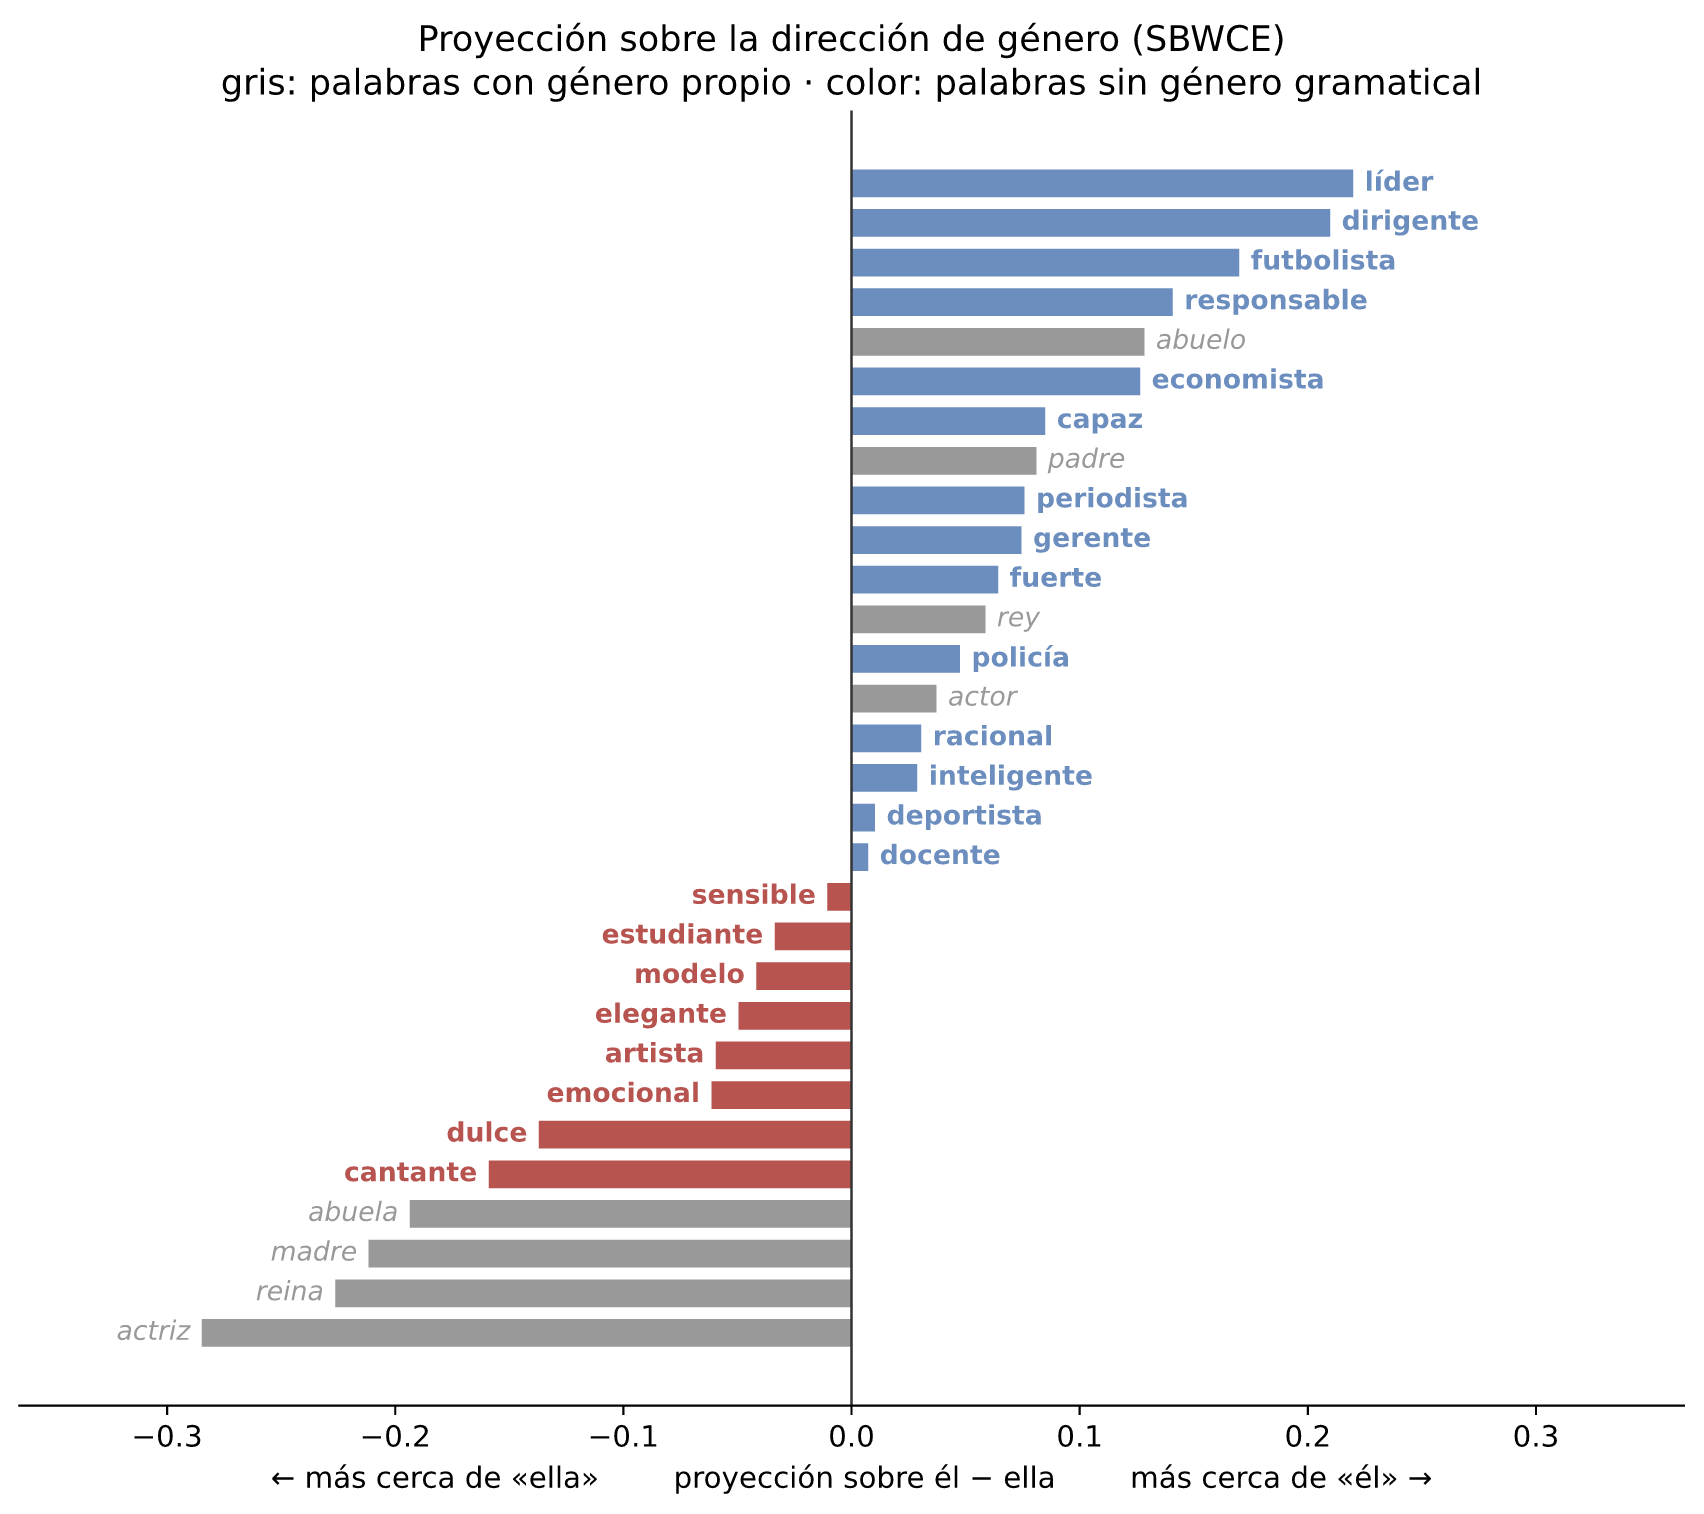

In [26]:
def eje(kv, positiva, negativa):
    d = kv[positiva] - kv[negativa]
    return d / np.linalg.norm(d)

def proyeccion(kv, palabra, direccion):
    v = kv[palabra]
    return float(v @ direccion / np.linalg.norm(v))

genero = eje(sbwce, "él", "ella")

# Referencias: palabras con género propio (esperamos que se inclinen)
con_genero = ["madre", "padre", "reina", "rey", "abuela", "abuelo", "actriz", "actor"]
# Palabras SIN género gramatical: sustantivos invariables (el/la ___) y adjetivos invariables
neutras = ["cantante", "artista", "modelo", "estudiante", "docente", "deportista", "periodista",
           "policía", "gerente", "economista", "futbolista", "dirigente", "líder",
           "dulce", "emocional", "elegante", "sensible", "inteligente", "racional", "fuerte", "capaz", "responsable"]

palabras = con_genero + neutras
valores = {p: proyeccion(sbwce, p, genero) for p in palabras}
orden = sorted(palabras, key=valores.get)

fig, ax = plt.subplots(figsize=(9, 8))
for i, p in enumerate(orden):
    v = valores[p]
    color = GRIS if p in con_genero else (AZUL if v > 0 else ROJO)
    ax.barh(i, v, color=color, height=0.7)
    ax.text(v + (0.005 if v > 0 else -0.005), i, p, va="center", ha="left" if v > 0 else "right",
            fontsize=10, color=color, style="italic" if p in con_genero else "normal",
            fontweight="normal" if p in con_genero else "bold")
ax.axvline(0, color="#333", lw=1)
ax.set_yticks([]); ax.spines["left"].set_visible(False)
lim = max(abs(v) for v in valores.values()) + 0.08
ax.set_xlim(-lim, lim)
ax.set_xlabel("← más cerca de «ella»        proyección sobre él − ella        más cerca de «él» →")
ax.set_title("Proyección sobre la dirección de género (SBWCE)\ngris: palabras con género propio · color: palabras sin género gramatical")
plt.tight_layout(); plt.show()

**Una advertencia propia del español.** En inglés *doctor* o *engineer* no marcan género, pero en español `secretaria`, `ingeniero`, `jefa` o `capitán` sí: es esperable que se inclinen hacia un lado solo por concordancia gramatical (*ella es secretaria*, *él es ingeniero*). Incluso un sustantivo femenino como `cocina` aparece con *la* y podría acercarse a «ella» por pura gramática. Por eso aquí usamos palabras **sin género gramatical**: sustantivos invariables (*el/la periodista*, *el/la líder*) y adjetivos invariables (*dulce*, *fuerte*).

Las palabras en gris (`madre`, `rey`…) son la referencia: sí tienen género. Pero las palabras sin género **también se reparten**:

- hacia «ella»: `cantante`, `dulce`, `emocional`, `artista`, `elegante`, `modelo`;
- hacia «él»: `líder`, `dirigente`, `futbolista`, `responsable`, `economista`, `capaz`, `fuerte`. ¡`líder` y `dirigente` se inclinan **más** que `padre` o `rey`!

La gramática no explica esa diferencia: viene de **cómo se usan** esas palabras en los textos del corpus (de quién se habla cuando se habla de líderes o de cantantes). Algunas, como `docente` o `sensible`, quedan casi en 0. Volveremos a esto en la sección 9.

**Para pensar:** el pronombre «él» también se usa como genérico en muchos textos. ¿Cómo podría eso afectar este eje? Prueben con otro par, por ejemplo `eje(sbwce, "hombre", "mujer")`.

# 8. Analogías: el modelo del paralelogramo

> *a* es a *b* como *a\** es a **?**  →  buscamos el vector más cercano a **b − a + a\***

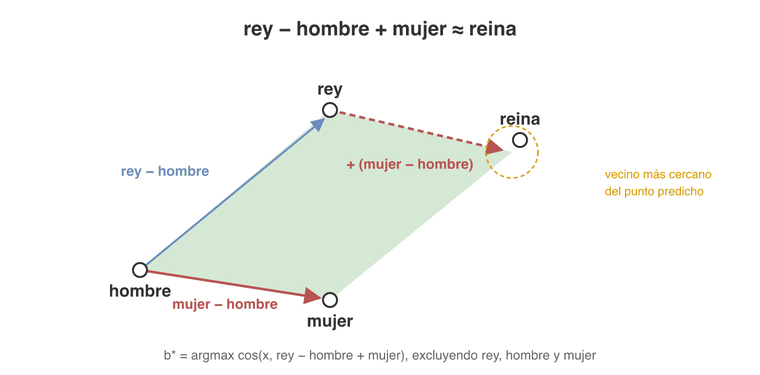

Hagamos la cuenta a mano con SBWCE. **Antes de ejecutar:** ¿qué palabra creen que quedará primera?

In [27]:
v = sbwce["rey"] - sbwce["hombre"] + sbwce["mujer"]
sbwce.similar_by_vector(v, topn=5)

[('rey', 0.7848702669143677),
 ('reina', 0.7493033409118652),
 ('princesa', 0.686154842376709),
 ('reyes', 0.6391469836235046),
 ('monarca', 0.6179779171943665)]

¡La más cercana es **`rey`**! El vector `rey − hombre + mujer` sigue estando muy cerca de `rey`. Por eso el método del paralelogramo **excluye las palabras de la pregunta**. Eso hace `most_similar(positive=..., negative=...)`:

In [28]:
def analogia(kv, a, b, a2, n=3):
    """a es a b como a2 es a ...  (b − a + a2, sin las palabras de entrada)"""
    faltan = [p for p in (a, b, a2) if p not in kv]
    if faltan:
        return f"fuera del vocabulario: {faltan}"
    return ", ".join(f"{p} ({s:.2f})" for p, s in kv.most_similar(positive=[b, a2], negative=[a], topn=n))

print("hombre : mujer :: rey : ?   →", analogia(sbwce, "hombre", "mujer", "rey"))

hombre : mujer :: rey : ?   → reina (0.75), princesa (0.69), reyes (0.64)


Las analogías funcionan porque ciertas **diferencias** entre vectores son aproximadamente constantes. Dibujemos varios pares masculino → femenino: si la relación es consistente, las flechas deberían ser casi paralelas y de largo parecido.

Para dibujar vectores de 300 dimensiones en 2D elegimos nosotros los dos ejes:

- **Eje horizontal:** la dirección `d` = promedio de las diferencias femenino − masculino de todos los pares.
- **Eje vertical:** lo que más varía entre las palabras **una vez quitada** la dirección `d` (por ejemplo, familia vs. realeza).

Para el eje vertical necesitamos separar cada vector **x** en dos partes: lo que apunta en la dirección `d` y el resto, perpendicular a `d`:

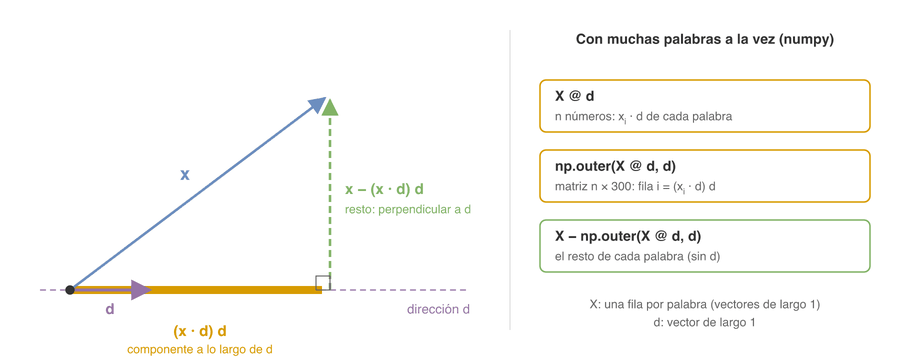

Si **x** y `d` tienen largo 1, el producto punto **x**·`d` es el coseno: cuánto avanza **x** en la dirección `d` (la sección 7 lo usó como proyección). Multiplicarlo por `d` da el vector "sombra" sobre el eje; restarlo deja el resto.

Veamos cada operación de numpy con dos vectores de 2 dimensiones, donde podemos verificar todo a mano. La dirección es el eje horizontal, `d = [1, 0]`:

In [29]:
X_demo = np.array([[3.0, 4.0],      # una fila por "palabra"
                   [1.0, 2.0]])
d_demo = np.array([1.0, 0.0])        # dirección de largo 1

print("X @ d             =", X_demo @ d_demo, "  ← un número por fila: cuánto avanza cada vector en la dirección d")
print("np.outer(X @ d, d) =\n", np.outer(X_demo @ d_demo, d_demo), "  ← fila i = (xᵢ · d) · d: la parte de cada vector a lo largo de d")
resto_demo = X_demo - np.outer(X_demo @ d_demo, d_demo)
print("X − outer         =\n", resto_demo, "  ← lo que queda: la parte perpendicular a d")
print("resto @ d         =", resto_demo @ d_demo, "  ← 0: el resto ya no tiene nada en la dirección d")

X @ d             = [3. 1.]   ← un número por fila: cuánto avanza cada vector en la dirección d
np.outer(X @ d, d) =
 [[3. 0.]
 [1. 0.]]   ← fila i = (xᵢ · d) · d: la parte de cada vector a lo largo de d
X − outer         =
 [[0. 4.]
 [0. 2.]]   ← lo que queda: la parte perpendicular a d
resto @ d         = [0. 0.]   ← 0: el resto ya no tiene nada en la dirección d


`np.outer(a, b)` construye la matriz cuyas filas son `a[i] * b`. Con `a = X @ d` (un número por palabra) y `b = d`, cada fila es la componente de esa palabra a lo largo de `d`, y `X − np.outer(X @ d, d)` la quita de todas las palabras a la vez.

### ¿Por qué no basta con `X @ d`?

`X @ d` es un **número** por palabra: dice *cuánto* avanza cada vector en la dirección `d` (la coordenada horizontal). Pero para quitar esa parte necesitamos un **vector** del mismo tamaño que **x**: ese número multiplicado por `d`. Restar directamente el número no tiene sentido geométrico, y numpy no siempre avisa. **Antes de ejecutar:** ¿qué creen que pasará?

In [30]:
print("X − (X @ d) =\n", X_demo - X_demo @ d_demo)

X − (X @ d) =
 [[ 0.  3.]
 [-2.  1.]]


¡No da error, pero el resultado está mal! Como `X_demo` tiene 2 columnas y `X_demo @ d_demo` tiene 2 números, numpy los resta **columna por columna** (*broadcasting*): a la primera columna le resta 3 y a la segunda, 1. Debería quedar `[[0, 4], [0, 2]]`. Con los vectores reales (16 palabras × 300 dimensiones) daría un error de tamaños. Por eso convertimos el número en vector con `np.outer`.

**¿Y para qué quitar `d` antes del PCA?** Para garantizar que los dos ejes del gráfico sean **perpendiculares**: el horizontal mide el género y el vertical, *todo lo demás*. Si aplicáramos PCA a los vectores originales, nada impediría que la dirección elegida para el eje vertical también contuviera parte de `d`, y el género aparecería mezclado en los dos ejes. (En estas 16 palabras el PCA casi no elige el género, pero quitar `d` lo garantiza en cualquier caso.)

Ahora con los vectores reales de SBWCE (300 dimensiones):

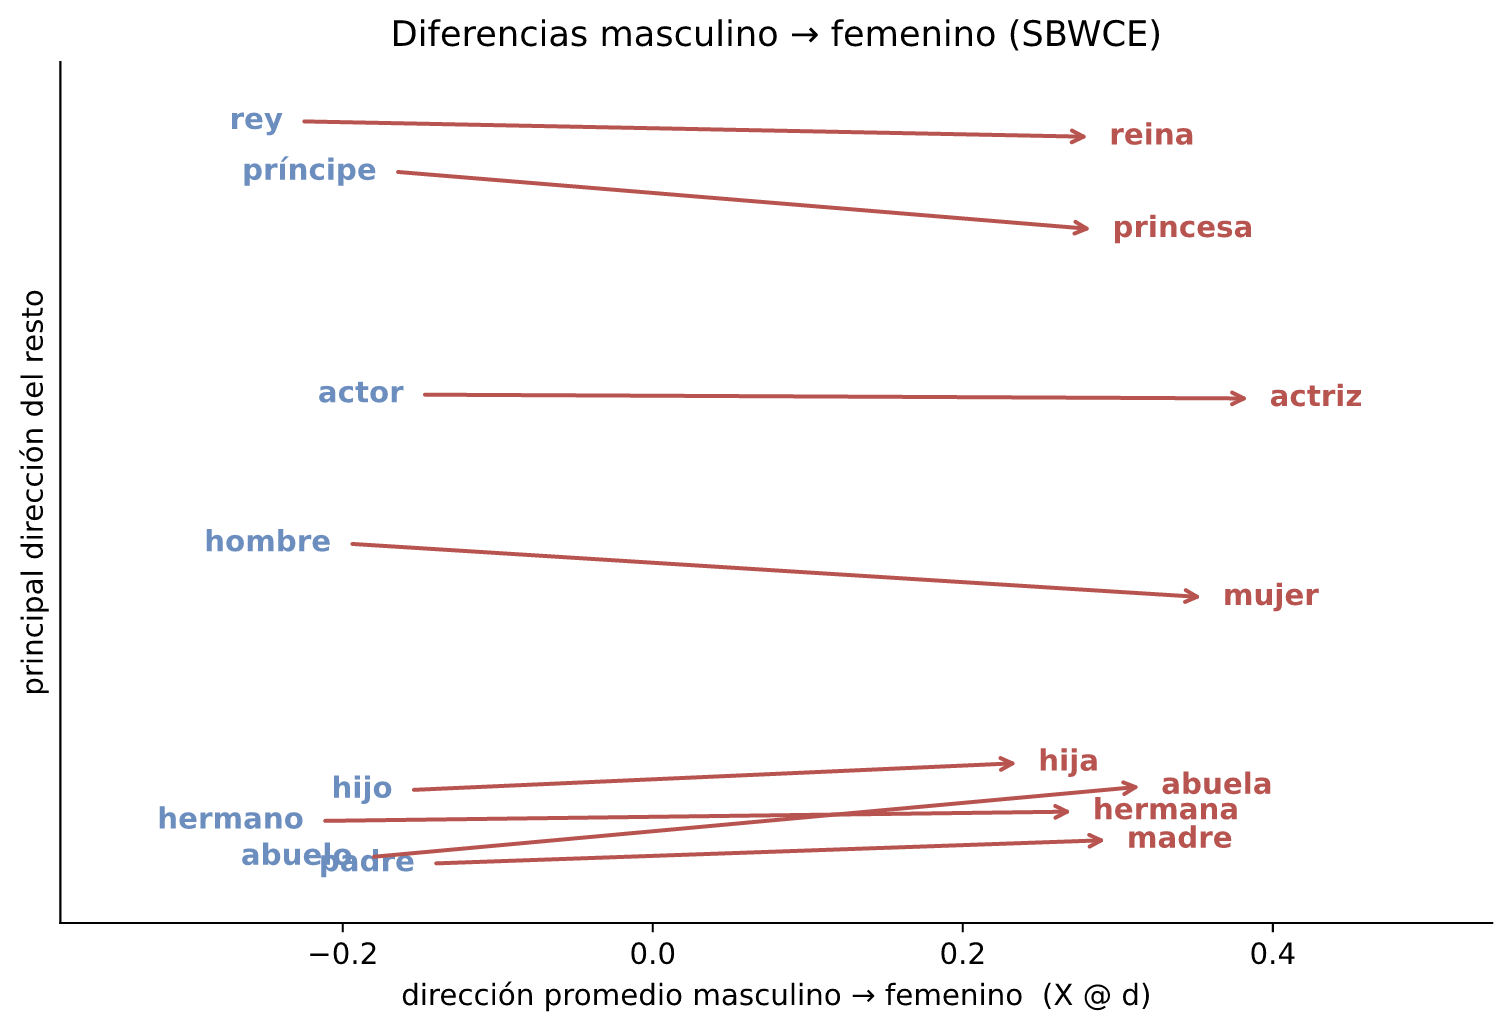

In [31]:
pares_genero = [("hombre", "mujer"), ("rey", "reina"), ("padre", "madre"), ("hijo", "hija"),
                ("hermano", "hermana"), ("abuelo", "abuela"), ("actor", "actriz"), ("príncipe", "princesa")]
palabras_pg = [p for par in pares_genero for p in par]

# 0. Vectores de largo 1 (una fila por palabra): así el producto punto es un coseno
unit = lambda p: sbwce[p] / np.linalg.norm(sbwce[p])
X = np.array([unit(p) for p in palabras_pg])                      # 16 × 300

# 1. Eje horizontal: la diferencia promedio femenino − masculino, de largo 1
d = np.mean([unit(f) - unit(m) for m, f in pares_genero], axis=0)
d = d / np.linalg.norm(d)
x_coord = X @ d                                                  # 16 números: avance en la dirección d

# 2. Quitamos de cada palabra su componente en d
X_resto = X - np.outer(x_coord, d)                               # 16 × 300, perpendicular a d

# 3. Eje vertical: la dirección de mayor variación de lo que queda (PCA con 1 componente)
y_coord = PCA(n_components=1).fit_transform(X_resto)[:, 0]       # 16 números

pos = {p: (x, y) for p, x, y in zip(palabras_pg, x_coord, y_coord)}

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(x_coord, y_coord, s=0)   # fija los límites del gráfico (annotate no los ajusta)
for m, f in pares_genero:
    ax.annotate("", xy=pos[f], xytext=pos[m], arrowprops=dict(arrowstyle="->", color=ROJO, lw=1.5))
    ax.annotate(m, pos[m], xytext=(-6, 0), textcoords="offset points", ha="right", va="center", color=AZUL, fontweight="bold")
    ax.annotate(f, pos[f], xytext=(6, 0), textcoords="offset points", ha="left", va="center", color=ROJO, fontweight="bold")
ax.margins(x=0.25, y=0.08)
ax.set_xlabel("dirección promedio masculino → femenino  (X @ d)")
ax.set_ylabel("principal dirección del resto")
ax.set_yticks([])
ax.set_title("Diferencias masculino → femenino (SBWCE)")
plt.tight_layout(); plt.show()

Las flechas son casi horizontales y de largo parecido: todos los pares se desplazan aproximadamente **lo mismo** en la dirección `d`. En vertical, las palabras se ordenan por otro rasgo (familia, realeza, espectáculo) que no cambia al pasar de masculino a femenino: por eso quitamos `d` antes del PCA, para que el eje vertical no mezcle el género.

Eso es lo que aprovecha el paralelogramo: `rey − hombre + mujer` suma a `rey` (aproximadamente) la misma flecha que lleva de `hombre` a `mujer`.

### Una pequeña evaluación intrínseca

Los conjuntos de analogías sirven para **evaluar** embeddings sin entrenar ningún clasificador. Probemos una batería con relaciones de varios tipos, en los dos modelos. **Antes de ejecutar:** ¿cuál modelo creen que acertará más en cada tipo de relación?

Si alguna de las cuatro palabras de una analogía no está en el vocabulario del modelo, la tabla muestra **— OOV —** (*out of vocabulary*, "fuera del vocabulario"): el modelo no tiene vector para esa palabra, así que no puede resolver la analogía y no la contamos. Pasa porque el modelo de reseñas descartó las palabras con menos de 5 apariciones (`min_count=5`) y la versión de SBWCE que usamos solo guarda las 10.000 palabras más frecuentes.

In [32]:
bateria = [
    ("género",   "hombre", "mujer", "padre", "madre"),
    ("género",   "hombre", "mujer", "hijo", "hija"),
    ("género",   "hombre", "mujer", "rey", "reina"),
    ("género",   "hombre", "mujer", "él", "ella"),
    ("plural",   "niño", "niños", "casa", "casas"),
    ("plural",   "libro", "libros", "mesa", "mesas"),
    ("adjetivo", "rojo", "roja", "blanco", "blanca"),
    ("adjetivo", "bonito", "bonita", "nuevo", "nueva"),
    ("adverbio", "lento", "lentamente", "rápido", "rápidamente"),
    ("verbo",    "funciona", "funcionan", "llega", "llegan"),
    ("verbo",    "ir", "fue", "tener", "tuvo"),
    ("grado",    "bueno", "mejor", "malo", "peor"),
    ("grado",    "rápido", "rapidísimo", "bueno", "buenísimo"),
]

def evaluar(kv, bateria):
    filas, aciertos, total = {}, 0, 0
    for tipo, a, b, a2, esperado in bateria:
        if any(p not in kv for p in (a, b, a2, esperado)):
            filas[f"{a}:{b} :: {a2}:?"] = [tipo, esperado, "— OOV —", ""]
            continue
        top = kv.most_similar(positive=[b, a2], negative=[a], topn=1)[0][0]
        total += 1; aciertos += top == esperado
        filas[f"{a}:{b} :: {a2}:?"] = [tipo, esperado, top, "✔" if top == esperado else "✘"]
    return filas, aciertos, total

for nombre, kv in [("Reseñas (skip-gram)", skipgram), ("SBWCE (general)", sbwce)]:
    filas, ok, n = evaluar(kv, bateria)
    print(f"{nombre}: {ok}/{n} correctas")
    mostrar(filas, ["tipo", "esperado", "respuesta", ""])

Reseñas (skip-gram): 9/12 correctas


,tipo,esperado,respuesta,
hombre:mujer :: padre:?,género,madre,madre,✔
hombre:mujer :: hijo:?,género,hija,hija,✔
hombre:mujer :: rey:?,género,reina,— OOV —,
hombre:mujer :: él:?,género,ella,ella,✔
niño:niños :: casa:?,plural,casas,peces,✘
libro:libros :: mesa:?,plural,mesas,muebles,✘
rojo:roja :: blanco:?,adjetivo,blanca,blanca,✔
bonito:bonita :: nuevo:?,adjetivo,nueva,nueva,✔
lento:lentamente :: rápido:?,adverbio,rápidamente,rápidamente,✔
funciona:funcionan :: llega:?,verbo,llegan,llegan,✔


SBWCE (general): 11/11 correctas


,tipo,esperado,respuesta,
hombre:mujer :: padre:?,género,madre,madre,✔
hombre:mujer :: hijo:?,género,hija,hija,✔
hombre:mujer :: rey:?,género,reina,reina,✔
hombre:mujer :: él:?,género,ella,ella,✔
niño:niños :: casa:?,plural,casas,casas,✔
libro:libros :: mesa:?,plural,mesas,mesas,✔
rojo:roja :: blanco:?,adjetivo,blanca,blanca,✔
bonito:bonita :: nuevo:?,adjetivo,nueva,— OOV —,
lento:lentamente :: rápido:?,adverbio,rápidamente,rápidamente,✔
funciona:funcionan :: llega:?,verbo,llegan,llegan,✔


Cada modelo refleja **su corpus**:

- SBWCE (noticias, libros) resuelve mejor relaciones de género y gramática general (`reina` ni siquiera está en el vocabulario de las reseñas: OOV).
- El modelo de reseñas conoce vocabulario coloquial que SBWCE no tiene en sus 10.000 palabras (`rapidísimo`, `buenísimo`).

La evaluación intrínseca mide propiedades del espacio; no garantiza que el embedding sea útil para *nuestra* tarea. Para eso está la evaluación extrínseca (sección 11).

Algunas analogías propias del dominio de las reseñas. **Antes de ejecutar:** ¿cuál creen que fallará?

In [33]:
print("caro : barato :: grande : ?     →", analogia(skipgram, "caro", "barato", "grande"))
print("perro : perra :: gato : ?       →", analogia(skipgram, "perro", "perra", "gato"))
print("llegó : llegaron :: funcionó : ? →", analogia(skipgram, "llegó", "llegaron", "funcionó"))
print("bueno : malo :: rápido : ?      →", analogia(skipgram, "bueno", "malo", "rápido"))

caro : barato :: grande : ?     → pequeña (0.69), pequeño (0.69), mat (0.66)
perro : perra :: gato : ?       → gata (0.85), gatita (0.77), perrita (0.75)
llegó : llegaron :: funcionó : ? → funcionaron (0.77), funcionaban (0.72), funciono (0.70)
bueno : malo :: rápido : ?      → rapidísimo (0.68), enseguida (0.64), rapido (0.62)


Las tres primeras funcionan; la última no (`rapidísimo` en vez de `lento`). Que `caro → barato` funcione y `bueno → malo` no muestra que el paralelogramo es frágil: solo funciona cuando la relación es un desplazamiento **aproximadamente constante** en el espacio, y `bueno` y `malo` están casi en el mismo punto (sección 5).

Prueben sus propias analogías con `analogia(skipgram, a, b, a2)` o `analogia(sbwce, a, b, a2)`.

# 9. Sesgos en los embeddings

Los embeddings aprenden de cómo escribimos, incluyendo nuestros estereotipos. Bolukbasi et al. (2016) encontraron en embeddings de noticias en inglés analogías como *hombre : programador :: mujer : ama de casa*.

Probemos analogías de profesiones con SBWCE: **mujer − hombre + profesión**.

In [34]:
for profesion in ["doctor", "profesor", "jefe", "ingeniero", "presidente"]:
    print(f"hombre : mujer :: {profesion:>10} : ?   →", analogia(sbwce, "hombre", "mujer", profesion, n=5))

hombre : mujer ::     doctor : ?   → profesora (0.57), médico (0.57), Medicina (0.55), Doctor (0.52), Dr (0.52)
hombre : mujer ::   profesor : ?   → profesora (0.83), catedrático (0.68), Profesor (0.63), doctorado (0.58), docente (0.58)
hombre : mujer ::       jefe : ?   → Jefe (0.60), directora (0.58), secretaria (0.55), coordinador (0.51), comandante (0.51)
hombre : mujer ::  ingeniero : ?   → ingeniería (0.52), arquitecto (0.50), ingenieros (0.48), profesora (0.46), hija (0.46)
hombre : mujer :: presidente : ?   → presidenta (0.70), Presidente (0.66), presidencia (0.63), vicepresidente (0.63), expresidente (0.60)


Algunas respuestas son la forma femenina correcta (`presidenta`, `profesora`). Otras revelan asociaciones del corpus: `doctor` → `profesora`, `jefe` → `secretaria`, `ingeniero` → `arquitecto`/`profesora`. La figura de la sección 7 mostraba lo mismo desde otro ángulo.

**Para discutir:**
- Si usamos estos vectores para filtrar currículums o recomendar empleos, ¿qué podría pasar?
- ¿Es un problema del algoritmo, de los datos o de ambos? ¿Basta con "borrar" la dirección de género?

# 10. fastText: palabras que el modelo nunca vio

word2vec tiene un vector por palabra del vocabulario. Las reseñas están llenas de errores y alargamientos (*pesimooo*, *buenisimooo*): cualquier palabra nueva queda **fuera del vocabulario (OOV)**.

fastText arma el vector de una palabra sumando los vectores de sus **n-gramas de caracteres**:

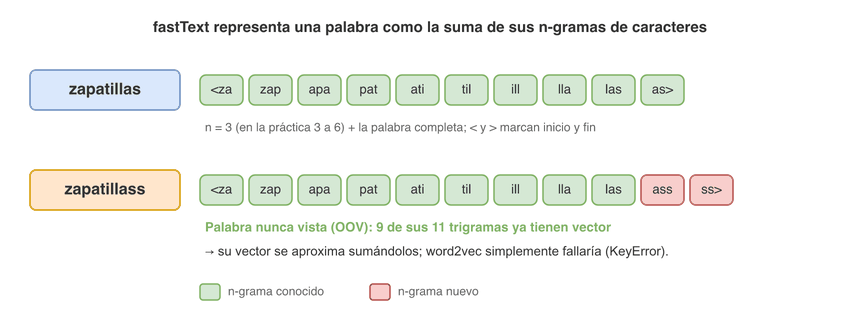

Entrenamos fastText con los mismos parámetros (tarda un poco más: aprende un vector por cada n-grama).

In [35]:
t0 = time.time()
fasttext = gensim.models.FastText(tokens_train, sg=1, min_n=3, max_n=5, **parametros).wv
print(f"fastText: {time.time() - t0:.1f} s")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


fastText: 81.6 s


**Antes de ejecutar:** ¿qué pasará con word2vec y con fastText ante estas palabras inventadas?

In [36]:
inventadas = ["pesimooo", "buenisimooo", "decepcionadisimo", "calidaaad", "zapatillass", "envioo"]
tabla = {p: ["sí" if p in skipgram else "no", vecinos(fasttext, p, 4)] for p in inventadas}
mostrar(tabla, ["¿en word2vec?", "vecinos con fastText"])

,¿en word2vec?,vecinos con fastText
pesimooo,no,pesimo (0.92) · pesima (0.83) · malisimo (0.82) · buenisimo (0.76)
buenisimooo,no,buenisimo (0.96) · buenisima (0.90) · buenisimos (0.87) · finisimo (0.83)
decepcionadisimo,no,decepciona (0.89) · decepcioné (0.88) · decepciono (0.88) · decepcionada (0.87)
calidaaad,no,calidsd (0.95) · calida (0.94) · calidad (0.91) · calidas (0.85)
zapatillass,no,zapatillas (0.96) · zapatilla (0.93) · zapata (0.84) · zapas (0.82)
envioo,no,envio (0.95) · envie (0.85) · envió (0.84) · envien (0.82)


Ninguna está en el vocabulario de word2vec (`skipgram["pesimooo"]` daría `KeyError`), pero fastText les asigna un vector razonable a partir de sus subpalabras. Es especialmente útil para texto informal, lenguas con mucha morfología (como el español) y dominios con vocabulario técnico.

# 11. Evaluación extrínseca: clasificar reseñas

Ahora usamos los embeddings en una tarea concreta: predecir si una reseña es **positiva** (4–5 ★) o **negativa** (1–2 ★); dejamos fuera las de 3 ★.

Para representar una reseña completa promediamos los vectores de sus palabras:

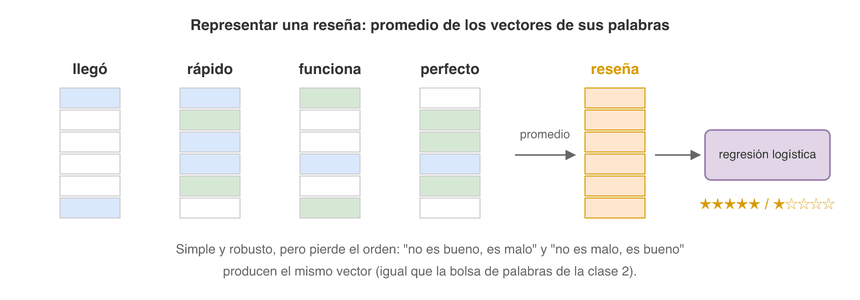

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score

def vector_documento(tokens, kv):
    """Promedio de los vectores de las palabras conocidas (ceros si no hay ninguna)."""
    vectores = [kv[p] for p in tokens if p in kv]
    return np.mean(vectores, axis=0) if vectores else np.zeros(kv.vector_size)

y_train_todas = np.array(resenas["train"]["label"])
y_test_todas = np.array(resenas["test"]["label"])
m_train, m_test = y_train_todas != 2, y_test_todas != 2          # sin las de 3 estrellas
y_train = (y_train_todas[m_train] >= 3).astype(int)               # 1 = positiva
y_test = (y_test_todas[m_test] >= 3).astype(int)
docs_train = [t for t, m in zip(tokens_train, m_train) if m]
docs_test = [t for t, m in zip(tokens_test, m_test) if m]
print(f"Entrenamiento: {len(docs_train):,} reseñas · Prueba: {len(docs_test):,}")

Entrenamiento: 160,000 reseñas · Prueba: 4,000


In [38]:
modelos = {"skip-gram": skipgram, "CBOW": cbow, "fastText": fasttext, "SBWCE": sbwce}
X_train = {n: np.array([vector_documento(t, kv) for t in docs_train]) for n, kv in modelos.items()}
X_test = {n: np.array([vector_documento(t, kv) for t in docs_test]) for n, kv in modelos.items()}

resultados = {}
for nombre in modelos:
    clf = LogisticRegression(max_iter=2000).fit(X_train[nombre], y_train)
    resultados[nombre] = accuracy_score(y_test, clf.predict(X_test[nombre]))

# Línea base de la clase 2: TF-IDF + la misma regresión logística
tfidf = TfidfVectorizer(analyzer=lambda t: t, min_df=5)
A_train, A_test = tfidf.fit_transform(docs_train), tfidf.transform(docs_test)
resultados["TF-IDF"] = accuracy_score(y_test, LogisticRegression(max_iter=2000).fit(A_train, y_train).predict(A_test))

mostrar({n: [a] for n, a in resultados.items()}, ["accuracy"], decimales=3)

,accuracy
skip-gram,0.889
CBOW,0.891
fastText,0.875
SBWCE,0.856
TF-IDF,0.920


In [39]:
A_tfidf = tfidf.transform(docs_train)
print(f"TF-IDF matrix size: {A_tfidf.shape[0]:,} documents × {A_tfidf.shape[1]:,} features")
print(f"Non-zero values: {A_tfidf.nnz:,}")

TF-IDF matrix size: 160,000 documents × 19,604 features
Non-zero values: 3,875,404


Algunas observaciones:

- Los embeddings entrenados con **reseñas** superan a **SBWCE**: el dominio importa más que el tamaño del corpus.
- Skip-gram y CBOW quedan muy cerca en esta tarea.
- Con 160.000 reseñas etiquetadas, **TF-IDF gana**. El promedio pierde información (orden, negaciones, palabras clave puntuales), y con tantos datos el clasificador aprende directamente qué palabras importan.

Entonces, ¿para qué sirven los embeddings aquí? **Antes de ejecutar:** ¿qué pasará si solo tenemos unas pocas reseñas etiquetadas?

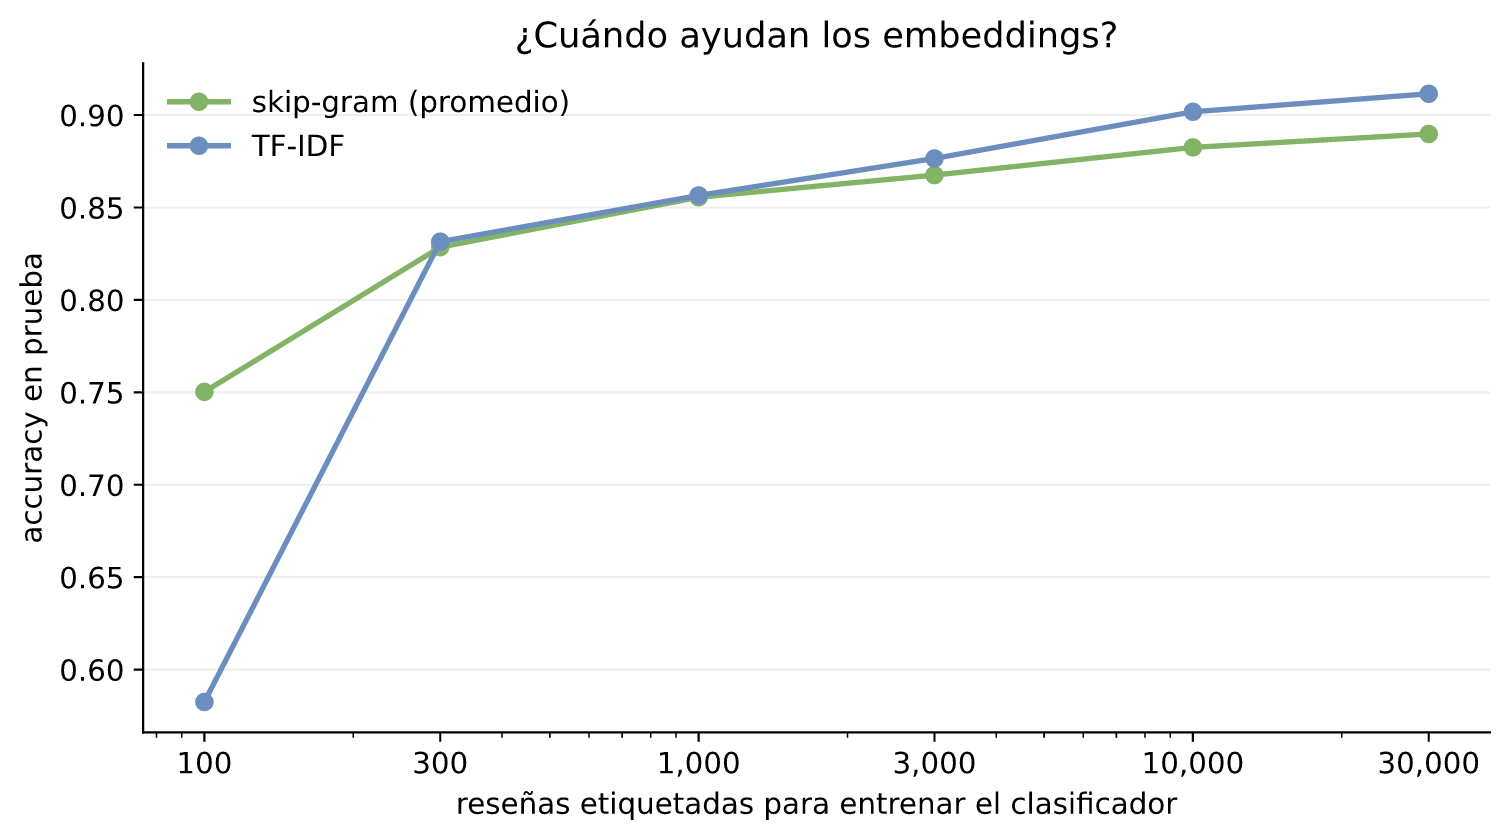

In [40]:
rng = np.random.default_rng(0)
orden = rng.permutation(len(docs_train))
tamanos = [100, 300, 1000, 3000, 10000, 30000]
curvas = {"skip-gram (promedio)": [], "TF-IDF": []}

for n in tamanos:
    i = orden[:n]
    clf = LogisticRegression(max_iter=2000).fit(X_train["skip-gram"][i], y_train[i])
    curvas["skip-gram (promedio)"].append(accuracy_score(y_test, clf.predict(X_test["skip-gram"])))
    tv = TfidfVectorizer(analyzer=lambda t: t)
    A = tv.fit_transform([docs_train[j] for j in i])
    clf = LogisticRegression(max_iter=2000).fit(A, y_train[i])
    curvas["TF-IDF"].append(accuracy_score(y_test, clf.predict(tv.transform(docs_test))))

fig, ax = plt.subplots(figsize=(8, 4.5))
for (nombre, valores), color in zip(curvas.items(), [VERDE, AZUL]):
    ax.plot(tamanos, valores, "o-", color=color, lw=2, label=nombre)
ax.set_xscale("log"); ax.set_xticks(tamanos); ax.set_xticklabels([f"{t:,}" for t in tamanos])
ax.set_xlabel("reseñas etiquetadas para entrenar el clasificador"); ax.set_ylabel("accuracy en prueba")
ax.legend(frameon=False); ax.grid(axis="y", color="#eee")
ax.set_title("¿Cuándo ayudan los embeddings?")
plt.tight_layout(); plt.show()

Con **pocas etiquetas** (100 reseñas), los embeddings ganan con claridad; alrededor de 1.000 las curvas se cruzan. Con pocos ejemplos, el clasificador ve `excelente` en entrenamiento y generaliza a `estupendo`, porque sus vectores ya están cerca. TF-IDF solo conoce las palabras que vio etiquetadas. Ese conocimiento lo aprendió word2vec **sin etiquetas**, a partir de texto crudo: es la gran idea del aprendizaje de representaciones (y de los modelos preentrenados que veremos más adelante).

Con muchas etiquetas, TF-IDF alcanza y supera al promedio de embeddings, que es una representación muy simple del documento.

# Resumen

- Un vector *one-hot* no expresa parecido: todas las palabras son ortogonales. Un **embedding** es un vector denso y corto cuyas direcciones capturan parecidos de uso.
- word2vec es **autosupervisado**: la ventana de contexto convierte texto crudo en ejemplos (palabra, contexto). **Skip-gram** predice el contexto desde la palabra; **CBOW**, la palabra desde el contexto.
- El clasificador es una regresión logística sobre **σ(c·w)**, con **muestreo negativo**. Las palabras que comparten contextos terminan cerca.
- CBOW es más rápido; skip-gram trata mejor las palabras poco frecuentes. Similitud distribucional ≠ sinonimia (`bueno` ≈ `malo`).
- Para mirar un espacio: vecinos, proyecciones 2D (con cautela) y proyecciones sobre direcciones elegidas.
- Las **analogías** (paralelogramo, excluyendo las palabras de entrada) son una evaluación intrínseca; reflejan el corpus, **incluidos sus sesgos**.
- **fastText** usa subpalabras y puede representar palabras fuera del vocabulario.
- En clasificación, el promedio de embeddings ayuda sobre todo cuando hay **pocas etiquetas**; con muchas, TF-IDF puede ganar.
- Limitación pendiente: un solo vector por palabra (`banco` de sentarse y de dinero). Los embeddings **contextuales** (transformers) la resuelven.

# Lecturas

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing*, 3.ª ed. (borrador). Capítulo *Embeddings* (word2vec, visualización, analogías, sesgos). https://web.stanford.edu/~jurafsky/slp3/
- Mikolov, T. et al. (2013). *Efficient Estimation of Word Representations in Vector Space* y *Distributed Representations of Words and Phrases and their Compositionality*.
- Bojanowski, P. et al. (2017). *Enriching Word Vectors with Subword Information* (fastText).
- Bolukbasi, T. et al. (2016). *Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings*.
- Cardellino, C. (2016). *Spanish Billion Words Corpus and Embeddings*. https://crscardellino.ar/SBWCE/

# Opcional — Para explorar

## A. El tamaño de la ventana

En las diapositivas: una ventana **corta** favorece palabras intercambiables (similitud); una **larga**, palabras del mismo tema (relación temática), como los documentos-contexto de la clase 2. Comparemos `window=2` con `window=10` (tarda unos minutos).

In [41]:
sin_ventana = {k: v for k, v in parametros.items() if k != "window"}
ventana_2 = gensim.models.Word2Vec(tokens_train, sg=1, window=2, **sin_ventana).wv
ventana_10 = gensim.models.Word2Vec(tokens_train, sg=1, window=10, **sin_ventana).wv
comparar(["lavar", "libro", "regalo", "batería"], {"ventana 2": ventana_2, "ventana 10": ventana_10}, n=6)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

,n,ventana 2,ventana 10
lavar,328,limpiar (0.76) · secar (0.73) · plegar (0.72) · aplicar (0.71) · planchar (0.71) · tender (0.71),lavadora (0.79) · lavarlo (0.74) · lava (0.73) · mojar (0.72) · lavavajillas (0.72) · lavaplatos (0.72)
libro,4009,cómic (0.75) · adictivo (0.72) · argumento (0.72) · cuento (0.71) · cuadernillo (0.71) · ameno (0.71),ameno (0.79) · escritor (0.77) · cuento (0.77) · cuadernillo (0.76) · literatura (0.76) · entretenido (0.75)
regalo,4576,regalar (0.79) · regalito (0.76) · cumpleaños (0.75) · encargo (0.73) · bautizo (0.73) · noel (0.73),regalar (0.86) · cumpleaños (0.81) · reyes (0.78) · regalito (0.77) · sobrina (0.76) · destinataria (0.76)
batería,4479,bateria (0.89) · pila (0.78) · carga (0.75) · autonomía (0.75) · baterías (0.70) · duración (0.70),bateria (0.85) · autonomía (0.82) · duración (0.78) · carga (0.77) · agota (0.76) · cargarla (0.74)


Con ventana 2, `lavar` se parece a `limpiar` o `secar` (acciones que ocupan el mismo lugar en la oración); con ventana 10 aparecen `lavadora` o `encoge` (cosas de las que se habla al lavar). Con `libro` pasa algo parecido: `cuento`, `cómic` vs. `autor`, `escritor`.

## B. Otros experimentos

Cuatro experimentos para hacer por su cuenta. Primero anticipen el resultado; después abran el desplegable para comparar con lo que obtuvimos nosotros (los números exactos pueden variar un poco entre ejecuciones).

### B1. ¿Más dimensiones siempre es mejor?

Entrenen skip-gram con `vector_size` = 10, 50 y 300 (además del 100 que ya tenemos) y repitan la clasificación positivo/negativo de la sección 11. Miren también los vecinos de `rojo` y `bueno` en cada modelo.

<details><summary>Ver resultados esperados</summary>

| dimensiones | accuracy (pos/neg) | tiempo de entrenamiento |
|---|---|---|
| 10 | ≈ 0,79 | ≈ 15 s |
| 50 | ≈ 0,86 | ≈ 20 s |
| 100 | ≈ 0,89 | ≈ 25 s |
| 300 | ≈ 0,91 | ≈ 45 s |

- En esta tarea, **más dimensiones sí ayudan** a clasificar: con 300 el promedio de embeddings casi alcanza a TF-IDF (0,92). Pero el entrenamiento tarda el doble.
- Los **vecinos no mejoran igual**: los de `rojo` son buenos desde 10 dimensiones, mientras que los de `bueno` se vuelven más ruidosos con 300 (`majo`, `recomedable`…).
- Más dimensiones capturan más matices *si hay datos suficientes*. Y la evaluación intrínseca (vecinos) y la extrínseca (clasificación) no siempre van de la mano.

</details>

### B2. Clasificar las 5 clases de estrellas

Repitan la clasificación usando las 5 etiquetas (`y_train_todas`, `y_test_todas`) en vez de positivo/negativo, y miren la matriz de confusión (`sklearn.metrics.confusion_matrix`). ¿Qué clases se confunden más?

<details><summary>Ver resultados esperados</summary>

- La accuracy baja a **≈ 0,51** (TF-IDF llega a ≈ 0,55); por azar sería 0,20.
- Los **extremos** se aciertan bien (★ ≈ 68 %, ★★★★★ ≈ 65 %) y las clases **intermedias**, mal (★★, ★★★ y ★★★★ ≈ 40–44 %).
- Cerca del **80 % de los errores son a una sola estrella de distancia** (★★★★ ↔ ★★★★★, ★ ↔ ★★): el modelo capta la *dirección* del sentimiento, pero no su *intensidad*. Las clases vecinas usan un vocabulario muy parecido, y el promedio de palabras no distingue "bueno" de "muy bueno, pero…".
- Para discutir: el problema es casi **ordinal**; confundir ★ con ★★ no es tan grave como confundir ★ con ★★★★★, pero la accuracy los cuenta igual.

</details>

### B3. Promedio ponderado con TF-IDF

Hasta ahora el vector de una reseña es el **promedio simple** de sus palabras: todas pesan lo mismo. En *"el producto llegó roto y no funciona"*, `el`, `y` o `producto` (presentes en casi todas las reseñas) cuentan igual que `roto`.

La idea es combinar las dos clases: los embeddings dicen **qué significa** cada palabra, y TF-IDF dice **cuánto importa**. En vez de promediar, hacemos un **promedio ponderado**:

$$
\mathbf d = \frac{\sum_i \text{peso}_i \,\mathbf w_i}{\sum_i \text{peso}_i}
\qquad \text{con } \text{peso}_i = \text{tf-idf}(w_i) \text{ (o solo su IDF)}
$$

Las palabras frecuentes (IDF bajo) casi no aportan y las distintivas (IDF alto) empujan el vector del documento hacia su dirección. Pueden obtener los IDF de `tfidf.idf_` y `tfidf.get_feature_names_out()`. Comparen la accuracy con el promedio simple.

<details><summary>Ver resultados esperados</summary>

| representación | accuracy (pos/neg) |
|---|---|
| promedio simple | ≈ 0,89 |
| promedio ponderado por IDF | ≈ 0,88 |

**¡No mejora; empeora un poco!** La idea suena bien, pero en análisis de sentimiento varias palabras muy frecuentes son justamente las importantes: `no`, `muy`, `bien`, `pero`. El IDF les baja el peso *porque* aparecen en todas partes. Lección: una técnica que funciona en una tarea (por ejemplo, búsqueda de documentos por tema) no tiene por qué funcionar en otra; hay que medir.

</details>

### B4. Palabras polisémicas

Busquen los vecinos de palabras con varios sentidos en el modelo de reseñas (`carga`, `talla`, `pila`, `muñeca`, `banco`) y comparen con SBWCE. ¿Qué sentido domina en cada modelo?

<details><summary>Ver resultados esperados</summary>

- En las reseñas domina el sentido "de producto de Amazon" y el otro casi desaparece:
  - `carga` → cargador, recarga, batería (no la carga de un camión);
  - `talla` → xl, xxl, tallaje (no una escultura);
  - `pila` → pilas, batería, aaa (no "una pila de libros").
- `muñeca` **mezcla** sentidos: parte del cuerpo (correa, cintura, pierna) y juguete (vestida).
- `banco` aparece solo ~100 veces en las reseñas y sus vecinos casi no tienen sentido; en SBWCE debería dominar el sentido financiero.
- Un embedding estático guarda **un solo vector por palabra**, dominado por el sentido más frecuente *en ese corpus*. Es la limitación que resuelven los embeddings contextuales.

</details>